# KION: автоматизация порождения признаков для ранкера (AutoFE + GNN)

Экспериментальный ноутбук — **основная часть исследования**. Бейзлайн (46 ручных признаков,
двухэтапная модель iALS+Pop → CatBoost YetiRank, временной протокол без утечек) зафиксирован
в отдельном ноутбуке `KION_RecSys_baseline_fixed.ipynb` и здесь **воспроизводится как опорная
рука A0** для честного сравнения.

## Исследовательский вопрос

Можно ли автоматизировать построение признаков двухэтапной рекомендательной системы
(или заменить их обучаемыми представлениями) **без потери качества относительно сильного
ручного набора** — при строгом временном протоколе и без утечек?

## Метод (две автоматические руки + сравнение)

1. **Spec-пространство + компилятор.** Признак описывается декларативной спекой
   `(связь user→категория) × (окно/затухание) × (условие) × (агрегат)`. Компилятор считает
   значения спеки as-of (только по истории до cutoff) для любых пар (user, item).
   Прямые связи user–item исключены: в KION пары глобально уникальны и просмотренное
   фильтруется из рекомендаций — такие признаки тождественны нулю.
2. **GNN-компилятор.** Гетерогенный граф (users, items, значения категорий), 2-слойная
   R-GCN (чистый PyTorch), обучение — link prediction на истории до cutoff (зеркально iALS).
   Производные для пары: dot, cos, L2, нормы, близость пользователя к категориям кандидата.
3. **Двухступенчатый отбор.** IG-скрининг на OOF-парах → дедупликация (избыточность внутри
   кандидатов и клоны ручных 46) → wrapper: ΔNDCG@10 **настоящего ранкера на реальных
   кандидатах** (iALS∪Pop), блоками + жадный отбор при фиксированном бюджете фитов.
4. **Финальные руки (полные данные, один протокол):**
   `A0` 46 ручных · `A_GNN` 46+GNN-производные · `A_AutoFE` 46+найденные спеки · `A_All` 46+всё.

## Гипотезы

* **H1**: поиск находит user×category-агрегаты (отсутствуют в ручном наборе) и даёт прирост NDCG@10 на тесте.
* **H2**: сигнал отбора важен — IG на случайных негативах расходится с пользой на кандидатной популяции.
* **H3**: прирост ограничен потолком Candidate Recall@K генератора кандидатов.
* **H4**: повторный расчёт скрининга на сдвинутом окне (drift-диагностика) слабо меняет рейтинг кандидатов.

## Протокол (без утечек)

* Временной сплит: `train` (< 2021-08-09) / `valid` (7д) / `test` (7д), пары user-item уникальны глобально.
* Все признаки/модели для окна — только по истории до as-of; OOF-срез внутри train для обучения ранкера.
* Поиск признаков: **только на подвыборке пользователей с полными историями** (быстрая итерация),
  значения отобранных спеков пересчитываются на полных данных на каждом cutoff.
* Отбор — только на valid (wrapper, бюджет фитов зафиксирован заранее); **test — один заход в конце**.
* GNN/iALS переобучаются на каждом cutoff зеркально: valid-стадия — по train; тестовая — по train+valid.

## Как запускать

* **Kaggle, 2×T4**: Settings → Accelerator = GPU T4 x2, Internet = On → Run All. Полный прогон ~2.5–4 ч.
  Артефакты: `autofe_artifacts/` (results.csv, selected_specs.json, search_log.json, важности, summary).
* **FAST_RUN = True** (ячейка конфигурации): подвыборка 5K пользователей, урезанные бюджеты —
  проверка всего пайплайна за ~10–15 минут. Метрики FAST-режима не характеризуют исследование.
* Порядок стадий: поиск (подвыборка) → финальные руки (полные данные) → test-оценка один раз.
* **Перезапуск после смерти ядра**: просто Run All — завершённый поиск (`search_artifacts.json`)
  и собранные фреймы/руки (`autofe_artifacts/ckpt/`) переиспользуются с диска, каждый фит
  ранкера чекпоинтится, большие фреймы собираются чанками. Принудительный пересчёт поиска —
  `CFG.force_search_rerun = True` (или удалить json).


In [1]:
# Установка зависимостей (в Kaggle catboost/torch/tqdm уже есть, implicit — ставим)
%pip install -q implicit catboost tqdm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 58.2 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json

base = Path("/kaggle/working/autofe_artifacts")
print("Артефакты:", base, "| существует:", base.exists())
if base.exists():
    print("поиск (search_artifacts.json):", (base / "search_artifacts.json").exists())
    ckpt = base / "ckpt"
    if ckpt.exists():
        for name in ("valid_arms.json", "test_arms.json"):
            p = ckpt / name
            if p.exists():
                rows = json.loads(p.read_text(encoding="utf-8")).get("rows", [])
                print(f"  {name}: руки {[r.get('arm') for r in rows]}")
            else:
                print(f"  {name}: НЕТ")
        for pat in ("valid_*.cbm", "final_*.cbm", "_tmp*", "oof.parquet", "vp.parquet"):
            fs = sorted(ckpt.glob(pat))
            print(f"  {pat}: {len(fs)} шт. {[f.name for f in fs][:8]}")
        for d in ("cand_valid_parts", "cand_test_parts"):
            dd = ckpt / d
            print(f"  {d}: {len(list(dd.glob('*.parquet')))} частей" if dd.exists() else f"  {d}: НЕТ")

Артефакты: /kaggle/working/autofe_artifacts | существует: False


In [3]:
import gc
import json
import os
import subprocess
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 80)

TRACKER = {"stage": [], "seconds": [], "fits": 0}  # учёт вычислительных затрат


def track(stage, fn, *args, **kwargs):
    """Исполняет fn и фиксирует время стадии (для раздела «вычислительные затраты»)."""
    t0 = time.time()
    out = fn(*args, **kwargs)
    TRACKER["stage"].append(stage)
    TRACKER["seconds"].append(round(time.time() - t0, 1))
    print(f"[{stage}] завершено за {time.time() - t0:.1f} c")
    return out


def ram_gb():
    """Занятая/полная RAM — диагностика пиков памяти на тяжёлых стадиях."""
    try:
        import psutil
        m = psutil.virtual_memory()
        return f"RAM {m.used / 2**30:.1f}/{m.total / 2**30:.1f} ГБ"
    except Exception:
        return "RAM ?"

def _ram_trim():
    """Возврат освобождённой памяти ОС (malloc_trim glibc-арен) после больших del.

    Без этого RSS процесса не снижается между стадиями: pandas/numpy возвращают
    память в арены аллокатора, а не ОС, и следующий пик ложится на уже раздутый
    RSS — так умирает ядро при формально достаточном объёме свободной памяти.
    """
    gc.collect()
    try:
        import ctypes
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except Exception:
        pass


class CFG:
    seed = 20261020              # единый seed; сплит от него НЕ зависит (только datetime)

    # --- протокол ---
    k_recommend = 10
    n_train_negatives = 20

    # --- кандидаты ---
    n_ials_candidates = 100
    n_pop_candidates = 20
    n_pop_candidates_cold = 100

    # --- iALS (как в бейзлайне) ---
    als_factors = 32
    als_iterations = 15
    als_regularization = 0.1

    # --- CatBoost: финальные руки (как в бейзлайне) ---
    cb_seed_ensemble = 2
    cb_iterations = 1000
    cb_early_stopping = 100
    cb_learning_rate = 0.05
    cb_depth = 8
    cb_l2_leaf_reg = 5

    # --- фаза поиска (подвыборка) ---
    search_user_sample = 200_000   # пользователей с полными историями
    search_cb_iterations = 600     # итераций ранкера в wrapper-фитах
    search_cb_learning_rate = 0.05 # learning rate ранкера в wrapper-фитах
    search_cb_early_stopping = 60
    screen_survivors = 48          # размер короткого списка после IG-скрининга
    wrapper_block_size = 6         # спеков в блоке на первом проходе wrapper
    wrapper_max_fits = 50          # бюджет фитов wrapper (анти-переобучение отбора)
    max_selected_specs = 12        # бережливость: потолок размера S1
    greedy_min_gain = 0.00005      # минимальный прирост NDCG для принятия спеки
    force_search_rerun = False     # True = игнорировать кэш поиска и выполнить его заново

    # --- устойчивость к смерти ядра (полные данные) ---
    frame_chunk_rows = 3_000_000   # строк в чанке сборки больших кандидатных фреймов

    # --- spec-пространство ---
    spec_max_total = None          # None = полное пространство (~420 спеков)

    # --- GNN ---
    gnn_dim = 64
    gnn_layers = 2
    gnn_epochs = 5
    gnn_lr = 0.01
    gnn_neg_k = 10
    gnn_batch_edges = 200_000
    gnn_steps_per_epoch = 3

    # --- быстрый прогон ---
    fast_run = False

    artifacts_dir = "autofe_artifacts"


if CFG.fast_run:
    # «полные данные» в FAST = подвыборка 5K (влезает в маленькую память),
    # бюджеты урезаны; цель FAST — пройти ВСЕ ветки кода, не качество
    CFG.user_sample = 5_000
    CFG.search_user_sample = 5_000
    CFG.als_iterations = 3
    CFG.cb_iterations = 120
    CFG.cb_early_stopping = 30
    CFG.cb_depth = 6
    CFG.search_cb_iterations = 80
    CFG.search_cb_early_stopping = 20
    CFG.screen_survivors = 18
    CFG.wrapper_block_size = 4
    CFG.wrapper_max_fits = 14
    CFG.max_selected_specs = 5
    CFG.spec_max_total = 90
    CFG.gnn_dim = 16
    CFG.gnn_epochs = 2
    CFG.gnn_batch_edges = 50_000
else:
    CFG.user_sample = None

np.random.seed(CFG.seed)

ARTIFACTS_DIR = Path(CFG.artifacts_dir)
ARTIFACTS_DIR.mkdir(exist_ok=True)

print(f"Конфигурация готова. FAST_RUN = {CFG.fast_run}, seed = {CFG.seed}")


Конфигурация готова. FAST_RUN = False, seed = 20261020


In [4]:
from catboost import CatBoostRanker, Pool


def _list_gpu_devices():
    """Список индексов GPU (nvidia-smi); пустой список = GPU недоступен."""
    try:
        out = subprocess.run(
            ["nvidia-smi", "--query-gpu=index", "--format=csv,noheader"],
            capture_output=True, text=True, timeout=15,
        )
        if out.returncode != 0:
            return []
        return [ln.strip() for ln in out.stdout.splitlines() if ln.strip()]
    except Exception:
        return []


CB_DEVICES = _list_gpu_devices()
CB_TASK_TYPE = "GPU" if CB_DEVICES else "CPU"

# Как в бейзлайне: CatBoost обучает одну модель на одном устройстве, поэтому
# 2×T4 заняты seed-ансамблем (по модели на карту, скоры усредняются на инференсе).
CB_SEEDS = [CFG.seed + i for i in range(max(1, CFG.cb_seed_ensemble))]

if CB_TASK_TYPE == "GPU":
    CB_DEVICE_FOR = {s: CB_DEVICES[i % len(CB_DEVICES)] for i, s in enumerate(CB_SEEDS)}
    N_PARALLEL = min(len(CB_SEEDS), len(CB_DEVICES))
else:
    CB_DEVICE_FOR = {}
    N_PARALLEL = min(len(CB_SEEDS), max(1, (os.cpu_count() or 2) // 4))

CB_THREADS_PER_MODEL = max(1, (os.cpu_count() or 2) // N_PARALLEL)

# GNN обучается на первой доступной карте (вторая остаётся CatBoost-ансамблю)
GNN_DEVICE = "cuda:0" if CB_DEVICES else "cpu"

print(f"CatBoost: {CB_TASK_TYPE}, devices: {CB_DEVICES or '-'}, ансамбль {len(CB_SEEDS)} (seeds={CB_SEEDS})")
print(f"GNN устройство: {GNN_DEVICE}")


CatBoost: GPU, devices: ['0', '1'], ансамбль 2 (seeds=[20261020, 20261021])
GNN устройство: cuda:0


In [5]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

from tqdm.auto import tqdm

COMMIT = "f69775be31fa5779907cf0a92ddedb70037fb5ae"
DATASET_URL = f"https://raw.githubusercontent.com/irsafilo/KION_DATASET/{COMMIT}/data_en.zip"

DATA_DIR = Path.cwd() / "data" / "data_en"
ARCHIVE_PATH = DATA_DIR.parent / "data_en.zip"


def download_progress(block_num, block_size, total_size):
    if total_size > 0:
        downloaded = min(block_num * block_size, total_size)
        progress_bar.total = total_size
        progress_bar.update(downloaded - progress_bar.n)


if not (DATA_DIR / "interactions.csv").exists():
    DATA_DIR.parent.mkdir(parents=True, exist_ok=True)

    if not ARCHIVE_PATH.exists():
        print("Скачивание data_en.zip…")
        with tqdm(total=0, unit="B", unit_scale=True, unit_divisor=1024, desc="Загрузка") as progress_bar:
            urlretrieve(DATASET_URL, ARCHIVE_PATH, reporthook=download_progress)
        print("Скачивание завершено!")

    print("Распаковка архива…")
    with ZipFile(ARCHIVE_PATH) as archive:
        archive.extractall(DATA_DIR.parent)
    print("Распаковка завершена!")
else:
    print(f"Датасет уже загружен: {DATA_DIR}")
print(f"Каталог с данными: {DATA_DIR.resolve()}")


Скачивание data_en.zip…


Загрузка: 0.00B [00:00, ?B/s]

Скачивание завершено!
Распаковка архива…
Распаковка завершена!
Каталог с данными: /kaggle/working/data/data_en


In [6]:
DATA_DIR = Path.cwd() / "data" / "data_en"

INTERACTIONS_PATH = DATA_DIR / "interactions.csv"
USERS_PATH = DATA_DIR / "users_en.csv"
ITEMS_PATH = DATA_DIR / "items_en.csv"

for path in [INTERACTIONS_PATH, USERS_PATH, ITEMS_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Не найден файл: {path}")


def load_metadata(path, id_name):
    df = pd.read_csv(path, low_memory=False)
    unnamed = [c for c in df.columns if str(c).startswith("Unnamed:")]
    df = df.drop(columns=unnamed, errors="ignore")
    if id_name not in df.columns:
        df = df.rename(columns={df.columns[0]: id_name})
    return df


users = load_metadata(USERS_PATH, "user_id")
items = load_metadata(ITEMS_PATH, "item_id")
interactions = pd.read_csv(INTERACTIONS_PATH, low_memory=False)

if "last_watch_dt" in interactions.columns:
    interactions = interactions.rename(columns={"last_watch_dt": "datetime"})
interactions["datetime"] = pd.to_datetime(interactions["datetime"], errors="coerce")

# FAST: «полные данные» = подвыборка пользователей с полными историями
if CFG.user_sample is not None and interactions["user_id"].nunique() > CFG.user_sample:
    keep_users = (
        pd.Index(interactions["user_id"].unique())
        .to_series()
        .sample(CFG.user_sample, random_state=CFG.seed)
        .to_numpy()
    )
    interactions = interactions[interactions["user_id"].isin(keep_users)].reset_index(drop=True)
    users = users[users["user_id"].isin(keep_users)].reset_index(drop=True)
    items = items[items["item_id"].isin(interactions["item_id"].unique())].reset_index(drop=True)
    print(f"FAST_RUN: оставлено {CFG.user_sample:,} пользователей")

print(f"Interactions: {interactions.shape}, Users: {users.shape}, Items: {items.shape}")
print(f"Период: {interactions['datetime'].min().date()} — {interactions['datetime'].max().date()}")


Interactions: (5476251, 5), Users: (840197, 5), Items: (15963, 16)
Период: 2021-03-13 — 2021-08-22


In [7]:
def clean_kion_data(interactions, users, items):
    """Очистка KION (как в бейзлайн-ноутбуке; единственное место, где данные меняются)."""

    def clean_table(df):
        df = df.copy()
        df.columns = df.columns.str.strip()
        unnamed = [c for c in df.columns if c.lower().startswith("unnamed:")]
        df = df.drop(columns=unnamed, errors="ignore")
        df = df.dropna(axis=1, how="all")
        null_tokens = {"", "na", "n/a", "nan", "none", "null", "<na>", "__missing__"}
        for col in df.select_dtypes(include=["object", "string"]).columns:
            s = df[col].astype("string").str.strip()
            df[col] = s.mask(s.str.lower().isin(null_tokens), pd.NA)
        n_duplicates = int(df.duplicated().sum())
        df = df.drop_duplicates().copy()
        return df, n_duplicates

    interactions, dup_interactions = clean_table(interactions)
    users, dup_users = clean_table(users)
    items, dup_items = clean_table(items)

    if "datetime" not in interactions.columns:
        if "last_watch_dt" in interactions.columns:
            interactions = interactions.rename(columns={"last_watch_dt": "datetime"})
        else:
            raise ValueError("В interactions отсутствует datetime/last_watch_dt")
    if not {"user_id", "item_id", "datetime"}.issubset(interactions.columns):
        raise ValueError("Не хватает столбцов в interactions")
    if "user_id" not in users.columns or "item_id" not in items.columns:
        raise ValueError("В users/items отсутствует ключевой ID")

    interactions["datetime"] = pd.to_datetime(interactions["datetime"], errors="coerce")
    interactions = interactions.dropna(subset=["user_id", "item_id", "datetime"]).copy()

    for col in ["total_dur", "watched_pct"]:
        if col not in interactions.columns:
            raise ValueError(f"Отсутствует обязательный столбец {col}")
        interactions[col] = pd.to_numeric(interactions[col], errors="coerce")
    interactions.loc[interactions["total_dur"] <= 0, "total_dur"] = np.nan
    interactions.loc[~interactions["watched_pct"].between(0, 100), "watched_pct"] = np.nan
    interactions["total_dur_missing"] = interactions["total_dur"].isna().astype("int8")
    interactions["watched_pct_missing"] = interactions["watched_pct"].isna().astype("int8")

    date_min = interactions["datetime"].min().normalize()
    date_max = interactions["datetime"].max().normalize()
    observation_days = (date_max - date_min).days + 1
    outlier_mask = interactions["total_dur"] > observation_days * 24 * 60 * 60
    interactions = interactions.loc[~outlier_mask].copy()

    duplicate_pairs = int(interactions.duplicated(["user_id", "item_id"]).sum())
    if duplicate_pairs:
        raise ValueError(f"Повторные пары user-item: {duplicate_pairs:,}")

    users = users.dropna(subset=["user_id"]).copy()
    items = items.dropna(subset=["item_id"]).copy()
    for df, key, name in [(users, "user_id", "users"), (items, "item_id", "items")]:
        if df[key].duplicated(keep=False).any():
            raise ValueError(f"В {name} повторяются значения {key}")

    if "release_year" in items.columns:
        years = pd.to_numeric(items["release_year"], errors="coerce")
        latest_observed_year = interactions["datetime"].dt.year.max()
        valid_year = (
            years.notna()
            & years.between(1888, latest_observed_year + 1)
            & np.isclose(years.fillna(0) % 1, 0)
        )
        items["release_year"] = years.where(valid_year)

    print(f"Очистка: дублей {dup_interactions}/{dup_users}/{dup_items}, "
          f"экстремальных длительностей удалено {int(outlier_mask.sum())}")
    print(f"interactions: {interactions.shape}, users: {users.shape}, items: {items.shape}")
    return interactions, users, items


interactions_clean, users_clean, items_clean = clean_kion_data(interactions, users, items)
del interactions, users, items
gc.collect()


def build_item_category_tables(items_meta):
    """Длинные таблицы item_id -> (тип связи, значение категории).

    genres/countries — мультитзначные (через запятую); content_type/age_rating —
    одиночные; release_decade — бакет года релиза. Метаданные объектов статичны
    во времени, поэтому их использование в as-of признаках безопасно (как в бейзлайне).
    """
    it = items_meta[["item_id"]].copy()
    ry = pd.to_numeric(items_meta["release_year"], errors="coerce") if "release_year" in items_meta else pd.Series(np.nan, index=it.index)

    def _split_multi(series, max_vals=8):
        s = series.astype("string").fillna("")
        parts = s.str.split(",", expand=False)
        vals = parts.apply(lambda lst: [x.strip() for x in lst if x and x.strip()][:max_vals] if isinstance(lst, list) else [])
        return vals

    tables = {}
    for rel, col in [("genre", "genres"), ("country", "countries")]:
        if col in items_meta.columns:
            long = pd.DataFrame({"item_id": it["item_id"].values, "cat_value": _split_multi(items_meta[col]).values})
            long = long.explode("cat_value", ignore_index=True)
            long = long.dropna().drop_duplicates()
            tables[rel] = long.reset_index(drop=True)
    for rel, col, mapper in [
        ("ctype", "content_type", lambda s: s.astype("string").str.strip()),
        ("age", "age_rating", lambda s: s.astype("string").str.strip()),
    ]:
        if col in items_meta.columns:
            vals = mapper(items_meta[col])
            tables[rel] = pd.DataFrame({"item_id": it["item_id"].values, "cat_value": vals.values}).dropna().reset_index(drop=True)
    decade = (ry // 10 * 10)
    tables["decade"] = pd.DataFrame({
        "item_id": it["item_id"].values,
        "cat_value": decade.map(lambda v: f"{int(v)}s" if pd.notna(v) else None).values,
    }).dropna().reset_index(drop=True)
    return tables


ITEM_CAT_TABLES = build_item_category_tables(items_clean)
print("Таблицы связей item->категория:",
      {k: len(v) for k, v in ITEM_CAT_TABLES.items()})


Очистка: дублей 0/0/0, экстремальных длительностей удалено 2
interactions: (5476249, 7), users: (840197, 5), items: (15963, 16)
Таблицы связей item->категория: {'genre': 40604, 'country': 18331, 'ctype': 15963, 'age': 15961, 'decade': 15865}


In [8]:
df = interactions_clean.copy()
df["datetime"] = pd.to_datetime(df["datetime"], errors="raise").dt.normalize()

last_date = df["datetime"].max()
test_start = last_date - pd.Timedelta(days=6)
valid_start = test_start - pd.Timedelta(days=7)

train = df[df["datetime"] < valid_start].copy()
valid = df[(df["datetime"] >= valid_start) & (df["datetime"] < test_start)].copy()
test = df[df["datetime"] >= test_start].copy()

assert len(train) + len(valid) + len(test) == len(df)
assert train["datetime"].max() < valid["datetime"].min()
assert valid["datetime"].max() < test["datetime"].min()


def assert_no_pair_overlap(a, b, name_a, name_b):
    merged = a[["user_id", "item_id"]].merge(b[["user_id", "item_id"]], on=["user_id", "item_id"], how="inner")
    assert merged.empty, f"Пары user-item пересекаются между {name_a} и {name_b}!"


assert_no_pair_overlap(train, valid, "train", "valid")
assert_no_pair_overlap(train, test, "train", "test")
assert_no_pair_overlap(valid, test, "valid", "test")

TRAIN_END = train["datetime"].max()
TRAIN_FEATURE_CUTOFF = TRAIN_END - pd.Timedelta(days=7)   # OOF-срез как в бейзлайне

print(f"train: {len(train):,} ({train['datetime'].min().date()}..{train['datetime'].max().date()}), "
      f"valid: {len(valid):,}, test: {len(test):,}")
print(f"OOF-срез внутри train: история <= {TRAIN_FEATURE_CUTOFF.date()}, "
      f"таргет {TRAIN_FEATURE_CUTOFF.date()}..{TRAIN_END.date()}")
print("Разбиение успешно: окна не пересекаются, пары user-item уникальны глобально.")

del df, interactions_clean
gc.collect()


train: 4,649,160 (2021-03-13..2021-08-08), valid: 402,653, test: 424,436
OOF-срез внутри train: история <= 2021-08-01, таргет 2021-08-01..2021-08-08
Разбиение успешно: окна не пересекаются, пары user-item уникальны глобально.


77

In [9]:
# ---------------------------------------------------------------------------
# Подвыборка для ФАЗЫ ПОИСКА: случайные пользователи с ПОЛНЫМИ историями
# (требование корректности из постановки задачи). Подвыборка влияет только на
# скорость поиска: отобранные спеки затем пересчитываются на полных данных.
# ---------------------------------------------------------------------------

all_users = np.sort(train["user_id"].unique())
if CFG.search_user_sample is not None and len(all_users) > CFG.search_user_sample:
    rng = np.random.default_rng(CFG.seed)
    s_user_ids = np.sort(rng.choice(all_users, size=CFG.search_user_sample, replace=False))
else:
    s_user_ids = all_users
    print("Поиск идёт по всем загруженным пользователям (подвыборка не требуется)")

S_USERS = set(s_user_ids)

S_TRAIN = train[train["user_id"].isin(S_USERS)].copy()
S_VALID = valid[valid["user_id"].isin(S_USERS)].copy()
S_TEST = test[test["user_id"].isin(S_USERS)].copy()

print(f"Фаза поиска: {len(s_user_ids):,} пользователей "
      f"({len(S_TRAIN):,} train / {len(S_VALID):,} valid / {len(S_TEST):,} test событий)")
print(f"Доля объёма train: {len(S_TRAIN) / max(1, len(train)) * 100:.1f}%")


Фаза поиска: 200,000 пользователей (1,093,526 train / 69,045 valid / 59,983 test событий)
Доля объёма train: 23.5%


# 1. Протокол и инфраструктура (переносится из бейзлайна без изменений)

Ниже — перенос протокольных блоков бейзлайн-ноутбука: метрики полного протокола,
`build_eval_pack` (warm-GT), PopularityModel, iALS, 46 ручных признаков (`build_rank_features`),
формирование обучающих групп (`make_rank_candidates`), кандидаты (`build_candidate_pairs`) и
скоринг топ-K. Изменения: `prepare_rank_frame`/`make_pool` параметризованы набором
признаков — финальные руки используют разные наборы (46 / +GNN / +AutoFE / +всё) при
**одинаковых** группах, кандидатах и сплите; `predict_topk` чанкует скоринг позиционно
(без полного среза признаков — механика памяти, на значения не влияет).

Ссылка на обоснования — в бейзлайн-ноутбуке (раздел 4): seen-фильтрация, warm-каталог,
as-of вычисление признаков, контроль непересечения окон assert-ами.


In [10]:
def precision_at_k(recommended, relevant, k):
    hits = sum(1 for x in recommended[:k] if x in relevant)
    return hits / k


def recall_at_k(recommended, relevant, k):
    if not relevant:
        return 0.0
    hits = sum(1 for x in recommended[:k] if x in relevant)
    return hits / len(relevant)


def average_precision_at_k(recommended, relevant, k):
    if not relevant:
        return 0.0
    hits = 0
    precision_sum = 0.0
    for i, x in enumerate(recommended[:k]):
        if x in relevant:
            hits += 1
            precision_sum += hits / (i + 1)
    return precision_sum / min(len(relevant), k)


def ndcg_at_k(recommended, relevant, k):
    dcg = sum(1.0 / np.log2(i + 2) for i, x in enumerate(recommended[:k]) if x in relevant)
    ideal_hits = min(len(relevant), k)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(ideal_hits))
    return dcg / idcg if idcg > 0 else 0.0


def mrr_at_k(recommended, relevant, k):
    for i, x in enumerate(recommended[:k]):
        if x in relevant:
            return 1.0 / (i + 1)
    return 0.0


def evaluate_recommendations(recs, ground_truth, k, catalog_size=None):
    """Средние метрики по всем пользователям с непустым ground truth."""
    users = list(ground_truth)
    out = {"users": len(users)}
    out[f"P@{k}"] = float(np.mean([precision_at_k(recs.get(u, []), ground_truth[u], k) for u in users]))
    out[f"R@{k}"] = float(np.mean([recall_at_k(recs.get(u, []), ground_truth[u], k) for u in users]))
    out[f"MAP@{k}"] = float(np.mean([average_precision_at_k(recs.get(u, []), ground_truth[u], k) for u in users]))
    out[f"NDCG@{k}"] = float(np.mean([ndcg_at_k(recs.get(u, []), ground_truth[u], k) for u in users]))
    out[f"MRR@{k}"] = float(np.mean([mrr_at_k(recs.get(u, []), ground_truth[u], k) for u in users]))
    out["avg_rec_len"] = float(np.mean([len(recs.get(u, [])) for u in users]))
    if catalog_size:
        recommended_items = {x for u in users for x in recs.get(u, [])}
        out[f"Coverage@{k}"] = len(recommended_items) / catalog_size
    return out


def candidate_recall(cands, ground_truth):
    """Полнота генератора кандидатов: доля релевантных объектов, попавших в кандидаты."""
    return float(np.mean([
        len(set(cands.get(u, [])) & rel) / len(rel) for u, rel in ground_truth.items()
    ]))


def build_eval_pack(history, target):
    """Оценочный пакет target-окна по истории history (как в бейзлайне)."""
    warm_items = np.sort(history["item_id"].unique())
    warm_set = set(warm_items)
    seen = history.groupby("user_id")["item_id"].agg(set).to_dict()

    warm_target = target[target["item_id"].isin(warm_set)]
    ground_truth = warm_target.groupby("user_id")["item_id"].agg(set).to_dict()
    eval_users = np.array(sorted(ground_truth))

    overlap = sum(len(ground_truth[u] & seen.get(u, set())) for u in eval_users)
    assert overlap == 0, "Найдены таргет-объекты, уже просмотренные в истории!"

    cold_users = int(sum(1 for u in eval_users if u not in seen))
    print(f"Окно: {len(target):,} событий | GT-пользователей: {len(eval_users):,} "
          f"(холодных: {cold_users:,}) | warm-каталог: {len(warm_items):,}")
    return {
        "warm_items": warm_items, "warm_set": warm_set, "seen": seen,
        "ground_truth": ground_truth, "eval_users": eval_users,
    }


print("Метрики и eval-pack готовы")


Метрики и eval-pack готовы


In [11]:
from scipy.sparse import csr_matrix
from implicit.als import AlternatingLeastSquares


class PopularityModel:
    """Топ объектов по числу взаимодействий в истории (опционально — окно days дней)."""

    def __init__(self, days=None, name="popularity"):
        self.days = days
        self.name = name

    def fit(self, history):
        h = history
        if self.days is not None:
            as_of = h["datetime"].max()
            h = h[h["datetime"] > as_of - pd.Timedelta(days=self.days)]
        counts = h.groupby("item_id").size().rename("cnt").reset_index()
        counts = counts.sort_values(["cnt", "item_id"], ascending=[False, True])
        self.ranking_ = counts["item_id"].to_numpy()
        return self

    def recommend(self, users, seen, k):
        recs = {}
        for u in users:
            s = seen.get(u, set())
            out = []
            for it in self.ranking_:
                if it not in s:
                    out.append(int(it))
                    if len(out) >= k:
                        break
            recs[u] = out
        return recs


def fit_ials(history, factors=CFG.als_factors, iterations=CFG.als_iterations,
             regularization=CFG.als_regularization, seed=CFG.seed):
    """implicit ALS на бинарной user-item матрице истории (как в бейзлайне)."""
    users_idx = pd.Index(history["user_id"].drop_duplicates())
    items_idx = pd.Index(history["item_id"].drop_duplicates())
    user_to_idx = {user_id: idx for idx, user_id in enumerate(users_idx)}
    item_to_idx = {item_id: idx for idx, item_id in enumerate(items_idx)}

    rows = history["user_id"].map(user_to_idx).to_numpy()
    cols = history["item_id"].map(item_to_idx).to_numpy()
    values = np.ones(len(history), dtype=np.float32)

    user_item = csr_matrix((values, (rows, cols)), shape=(len(users_idx), len(items_idx)), dtype=np.float32)
    user_item.sum_duplicates()
    user_item.data[:] = 1.0

    model = AlternatingLeastSquares(factors=factors, iterations=iterations,
                                    regularization=regularization, random_state=seed, use_gpu=False)
    model.fit(user_item, show_progress=False)

    return {"model": model, "user_to_idx": user_to_idx, "item_to_idx": item_to_idx,
            "user_item": user_item, "n_users": len(users_idx), "n_items": len(items_idx)}


def ials_top_lists(bundle, users, seen, k, popularity_order=None, chunk=2048):
    """Топ-k объектов по iALS-оценке; холодным — популярность (как в бейзлайне)."""
    model = bundle["model"]
    user_to_idx = bundle["user_to_idx"]
    item_to_idx = bundle["item_to_idx"]
    user_item = bundle["user_item"]

    item_ids_arr = np.zeros(len(item_to_idx), dtype=np.int64)
    for item_id, idx in item_to_idx.items():
        item_ids_arr[idx] = item_id

    warm = [u for u in users if u in user_to_idx]
    cold = [u for u in users if u not in user_to_idx]
    recs = {}

    if popularity_order is not None:
        for u in cold:
            s = seen.get(u, set())
            out = []
            for it in popularity_order:
                if it not in s:
                    out.append(int(it))
                    if len(out) >= k:
                        break
            recs[u] = out

    item_factors = model.item_factors
    kk = min(k, len(item_to_idx))

    for start in range(0, len(warm), chunk):
        chunk_users = warm[start:start + chunk]
        rows_idx = np.array([user_to_idx[u] for u in chunk_users], dtype=np.int64)
        scores = model.user_factors[rows_idx] @ item_factors.T
        hist_block = user_item[rows_idx].tocoo()
        scores[hist_block.row, hist_block.col] = -np.inf
        part = np.argpartition(-scores, kth=kk - 1, axis=1)[:, :kk]
        part_scores = np.take_along_axis(scores, part, axis=1)
        order = np.argsort(-part_scores, axis=1, kind="stable")
        top = np.take_along_axis(part, order, axis=1)
        for r, u in enumerate(chunk_users):
            recs[u] = [int(item_ids_arr[j]) for j in top[r]]
    return recs


print("PopularityModel и iALS готовы")


PopularityModel и iALS готовы


In [12]:
USER_CATEGORICAL = ["age", "income", "sex", "kids_flg"]
ITEM_CATEGORICAL = ["content_type", "age_rating", "for_kids", "genres", "countries"]

CATEGORICAL_FEATURES = (
    [f"u_{c}" for c in USER_CATEGORICAL] + [f"i_{c}" for c in ITEM_CATEGORICAL]
)

NUMERIC_FEATURES = [
    "has_user_metadata",
    "user_history_count", "user_n_items",
    "user_mean_watched_pct", "user_mean_logdur", "user_recency_days",
    "popularity_all", "popularity_1d", "popularity_7d", "popularity_30d",
    "log1p_popularity_all", "log1p_popularity_1d",
    "log1p_popularity_7d", "log1p_popularity_30d",
    "item_n_users", "item_mean_watched_pct", "item_mean_logdur", "item_recency_days",
    "item_gender_share", "item_rate_within_gender",
    "item_high_watch_rate_by_gender", "item_gender_count",
    "ials_score", "ials_available", "ials_user_known", "ials_item_known",
    "i_release_year", "i_release_year_missing",
]
NUMERIC_FEATURES += [f"u_{col}_missing" for col in USER_CATEGORICAL]
NUMERIC_FEATURES += [f"i_{col}_missing" for col in ITEM_CATEGORICAL]

FEATURES_46 = CATEGORICAL_FEATURES + NUMERIC_FEATURES   # ручной набор бейзлайна


def history_statistics(history, as_of, users):
    """Статистики пользователей/объектов/гендерные агрегаты — строго по history, as-of (из бейзлайна)."""
    h = history.copy()
    h["datetime"] = pd.to_datetime(h["datetime"]).dt.normalize()
    as_of = pd.Timestamp(as_of).normalize()
    h["total_dur"] = pd.to_numeric(h["total_dur"], errors="coerce")
    h["watched_pct"] = pd.to_numeric(h["watched_pct"], errors="coerce")
    h["_logdur"] = np.log1p(h["total_dur"].clip(lower=0))

    user_stats = (
        h.groupby("user_id").agg(
            user_history_count=("item_id", "size"),
            user_n_items=("item_id", "nunique"),
            user_mean_watched_pct=("watched_pct", "mean"),
            user_mean_logdur=("_logdur", "mean"),
            user_last_seen=("datetime", "max"),
        ).reset_index()
    )
    user_stats["user_recency_days"] = (as_of - user_stats["user_last_seen"]).dt.days.clip(lower=0)
    user_stats = user_stats.drop(columns="user_last_seen")

    item_stats = (
        h.groupby("item_id").agg(
            popularity_all=("user_id", "size"),
            item_n_users=("user_id", "nunique"),
            item_mean_watched_pct=("watched_pct", "mean"),
            item_mean_logdur=("_logdur", "mean"),
            item_last_seen=("datetime", "max"),
        ).reset_index()
    )
    item_stats["item_recency_days"] = (as_of - item_stats["item_last_seen"]).dt.days.clip(lower=0)
    item_stats = item_stats.drop(columns="item_last_seen")

    for days in [1, 7, 30]:
        window = h[(h["datetime"] > as_of - pd.Timedelta(days=days)) & (h["datetime"] <= as_of)]
        counts = window.groupby("item_id").size().rename(f"popularity_{days}d")
        item_stats = item_stats.merge(counts, on="item_id", how="left", validate="one_to_one")
        item_stats[f"popularity_{days}d"] = item_stats[f"popularity_{days}d"].fillna(0)

    for col in ["popularity_all", "popularity_1d", "popularity_7d", "popularity_30d"]:
        if col not in item_stats:
            item_stats[col] = 0
        item_stats[f"log1p_{col}"] = np.log1p(item_stats[col])

    sex_map = users[["user_id", "sex"]].drop_duplicates("user_id")
    hg = h[["user_id", "item_id", "watched_pct"]].merge(sex_map, on="user_id", how="left", validate="many_to_one")
    hg["sex_group"] = hg["sex"].astype("string").fillna("__MISSING__")
    hg["_high_watch"] = np.where(hg["watched_pct"].notna(), (hg["watched_pct"] > 90).astype(float), np.nan)

    gender_item = (
        hg.groupby(["item_id", "sex_group"], observed=True).agg(
            item_gender_count=("item_id", "size"),
            item_high_watch_rate_by_gender=("_high_watch", "mean"),
        ).reset_index()
    )
    item_totals = item_stats[["item_id", "popularity_all"]]
    gender_totals = hg.groupby("sex_group").size().rename("gender_total_count").reset_index()
    gender_item = gender_item.merge(item_totals, on="item_id", how="left").merge(gender_totals, on="sex_group", how="left")
    gender_item["item_gender_share"] = gender_item["item_gender_count"] / gender_item["popularity_all"].replace(0, np.nan)
    gender_item["item_rate_within_gender"] = gender_item["item_gender_count"] / gender_item["gender_total_count"].replace(0, np.nan)
    return user_stats, item_stats, gender_item


def build_rank_features(candidates, history, as_of, users, items, ials_bundle):
    """46 ручных признаков для пар (user, item) — дословно из бейзлайна."""
    user_stats, item_stats, gender_stats = history_statistics(history, as_of, users)

    data = candidates.copy()
    data = data.merge(user_stats, on="user_id", how="left", validate="many_to_one")
    data = data.merge(item_stats, on="item_id", how="left", validate="many_to_one")

    u_cols = ["user_id"] + [c for c in USER_CATEGORICAL if c in users.columns]
    u = users[u_cols].copy()
    u = u.rename(columns={c: f"u_{c}" for c in u.columns if c != "user_id"})
    data["has_user_metadata"] = data["user_id"].isin(users["user_id"]).astype("int8")
    data = data.merge(u, on="user_id", how="left", validate="many_to_one")
    for col in USER_CATEGORICAL:
        name = f"u_{col}"
        if name not in data:
            data[name] = "__MISSING__"
        data[f"{name}_missing"] = data[name].isna().astype("int8")
        data[name] = data[name].astype("string").fillna("__MISSING__")

    item_cols = [c for c in ["item_id", "content_type", "release_year", "age_rating", "for_kids", "genres", "countries"] if c in items.columns]
    it = items[item_cols].copy()
    it = it.rename(columns={c: f"i_{c}" for c in item_cols if c != "item_id"})
    data = data.merge(it, on="item_id", how="left", validate="many_to_one")

    if "i_release_year" not in data:
        data["i_release_year"] = np.nan
    data["i_release_year"] = pd.to_numeric(data["i_release_year"], errors="coerce")
    data["i_release_year_missing"] = data["i_release_year"].isna().astype("int8")
    for col in ITEM_CATEGORICAL:
        name = f"i_{col}"
        if name not in data:
            data[name] = "__MISSING__"
        data[f"{name}_missing"] = data[name].isna().astype("int8")
        data[name] = data[name].astype("string").fillna("__MISSING__")

    data["_sex_group"] = data["u_sex"].astype("string").fillna("__MISSING__")
    gender_merge = gender_stats.drop(columns=["popularity_all", "gender_total_count"], errors="ignore")
    data = data.merge(gender_merge, left_on=["item_id", "_sex_group"], right_on=["item_id", "sex_group"],
                      how="left", validate="many_to_one")
    data = data.drop(columns=["_sex_group", "sex_group"], errors="ignore")

    u_idx = data["user_id"].map(ials_bundle["user_to_idx"])
    i_idx = data["item_id"].map(ials_bundle["item_to_idx"])
    data["ials_user_known"] = u_idx.notna().astype("int8")
    data["ials_item_known"] = i_idx.notna().astype("int8")
    score = np.full(len(data), np.nan, dtype=np.float32)
    known = u_idx.notna() & i_idx.notna()
    positions = np.flatnonzero(known.to_numpy())
    if len(positions):
        u_arr = u_idx.loc[known].astype("int64").to_numpy()
        i_arr = i_idx.loc[known].astype("int64").to_numpy()
        model = ials_bundle["model"]
        score[positions] = np.sum(model.user_factors[u_arr] * model.item_factors[i_arr], axis=1)
    data["ials_available"] = np.isfinite(score).astype("int8")
    data["ials_score"] = np.nan_to_num(score, nan=0.0, posinf=0.0, neginf=0.0).astype("float32")

    count_cols = [c for c in data.columns
                  if c.startswith("popularity_") or c.startswith("log1p_popularity_")
                  or c in ["item_n_users", "user_history_count", "user_n_items"]]
    data[count_cols] = data[count_cols].fillna(0)
    return data


def prepare_rank_frame(frame, extra_num=None):
    """Приводит признаки к типам CatBoost: 46 ручных + extra_num (авто-блоки)."""
    need = FEATURES_46 + list(extra_num or [])
    missing = [c for c in need if c not in frame.columns]
    if missing:
        raise ValueError(f"Отсутствуют признаки (проверьте сборку): {missing}")
    for col in CATEGORICAL_FEATURES:
        frame[col] = frame[col].fillna("__MISSING__").astype("category")
    for col in NUMERIC_FEATURES + list(extra_num or []):
        frame[col] = pd.to_numeric(frame[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
    return frame


def make_pool(frame, features, cat_features=None):
    """Pool для CatBoostRanker с настраиваемым набором признаков (группы одинаковы между руками).

    Память: фреймы пар формируются в порядке group_id (make_rank_candidates нумерует
    группы последовательно, левые мерджи и parquet порядок строк не меняют), поэтому
    сортировка нужна редко — проверка монотонности дешевле полной копии sort_values
    (~5+ ГБ на полных данных). CatBoost требует монотонные блоки group_id, fallback
    сохраняет прежнее поведение, если порядок всё же нарушен.
    """
    cat_features = CATEGORICAL_FEATURES if cat_features is None else cat_features
    gid = frame["group_id"].to_numpy()
    if len(gid) > 1 and bool(np.any(gid[1:] < gid[:-1])):
        frame = frame.sort_values("group_id").reset_index(drop=True)
    return Pool(frame[features], label=frame["label"], group_id=frame["group_id"], cat_features=cat_features)


print(f"46 ручных признаков готовы (всего: {len(FEATURES_46)})")


46 ручных признаков готовы (всего: 46)


In [13]:
def make_rank_candidates(history, target, n_negatives=CFG.n_train_negatives, seed=CFG.seed):
    """Группы для обучения ранкера: таргет-окно + случайные негативы (из бейзлайна)."""
    history = history.copy()
    target = target.copy()
    history["datetime"] = pd.to_datetime(history["datetime"]).dt.normalize()
    target["datetime"] = pd.to_datetime(target["datetime"]).dt.normalize()

    catalog = np.sort(pd.Index(history["item_id"]).unique())
    catalog_set = set(catalog)
    seen_by_user = history.groupby("user_id")["item_id"].agg(set).to_dict()
    warm_target = target[target["item_id"].isin(catalog_set)]

    rng = np.random.default_rng(seed)
    records = []
    next_group = 0

    for user_id, group in warm_target.groupby("user_id", sort=False):
        positives = set(group["item_id"].unique())
        seen = seen_by_user.get(user_id, set())
        blocked = seen | positives

        negatives = set()
        attempts = 0
        while len(negatives) < n_negatives and attempts < 10:
            draws = rng.choice(catalog, size=max(128, 3 * n_negatives), replace=True)
            for item_id in draws:
                if item_id not in blocked:
                    negatives.add(item_id)
                    if len(negatives) >= n_negatives:
                        break
            attempts += 1

        if len(negatives) < n_negatives:
            remaining = np.array([x for x in catalog if x not in blocked and x not in negatives])
            need = min(n_negatives - len(negatives), len(remaining))
            if need:
                negatives.update(rng.choice(remaining, size=need, replace=False).tolist())

        if not negatives:
            continue
        for item_id in positives:
            records.append((next_group, user_id, item_id, 1))
        for item_id in negatives:
            records.append((next_group, user_id, item_id, 0))
        next_group += 1

    result = pd.DataFrame(records, columns=["group_id", "user_id", "item_id", "label"])
    if result.empty:
        raise ValueError("Не получилось сформировать ranking groups.")
    return result


def build_candidate_pairs(ials_lists, pop_ranking, users, seen):
    """Кандидаты ранкера: iALS top-N ∪ популярность (из бейзлайна)."""
    records = []
    for u in users:
        s = seen.get(u, set())
        ials_part = ials_lists.get(u, [])[: CFG.n_ials_candidates]
        for it in ials_part:
            records.append((u, int(it)))
        cand_set = set(ials_part)
        budget = CFG.n_pop_candidates if ials_part else CFG.n_pop_candidates_cold
        added = 0
        for it in pop_ranking:
            if added >= budget:
                break
            if it not in s and it not in cand_set:
                records.append((u, int(it)))
                cand_set.add(it)
                added += 1
    return pd.DataFrame(records, columns=["user_id", "item_id"])


def predict_topk(models, frame, features, k=CFG.k_recommend, chunk=2_000_000):
    """Скорит пары моделью/ансамблем (средний скор) — топ-k на пользователя (из бейзлайна).

    Память: чанки вырезаются позиционно (iloc[строки, позиции столбцов]) — полный срез
    frame[features] не копируется целиком; на скоры и топ-k это не влияет.
    """
    if not isinstance(models, (list, tuple)):
        models = [models]
    scores = np.empty(len(frame), dtype=np.float32)
    col_pos = [frame.columns.get_loc(c) for c in features]
    for start in range(0, len(frame), chunk):
        stop = min(start + chunk, len(frame))
        part = frame.iloc[start:stop, col_pos]
        scores[start:stop] = np.mean([m.predict(part) for m in models], axis=0)

    top = (
        pd.DataFrame({
            "user_id": frame["user_id"].to_numpy(),
            "item_id": frame["item_id"].to_numpy(),
            "score": scores,
        })
        .sort_values(["user_id", "score"], ascending=[True, False], kind="mergesort")
        .groupby("user_id", sort=False)
        .head(k)
    )
    return top.groupby("user_id")["item_id"].apply(list).to_dict()


def predict_topk_single(model, frame, features, k=CFG.k_recommend):
    """Топ-k одной моделью (для оценки межсидового разброса)."""
    return predict_topk([model], frame, features, k=k)


print("make_rank_candidates, build_candidate_pairs, predict_topk готовы")


make_rank_candidates, build_candidate_pairs, predict_topk готовы


# 2. Spec-пространство и компилятор

## Формализация

Агрегатный признак = декларативная спека:

```
(связь: user → категория объекта)  ×  (окно w или затухание d)  ×  (условие)  ×  (агрегат)
```

* **Связи** (косвенные, через метаданные объекта): `genre`, `country` (многозначные),
  `content_type`, `age_rating`, `release_decade`. Прямая связь user–item **исключена**:
  в KION пары глобально уникальны и просмотренное фильтруется — признак был бы тождественен нулю.
* **Окно**: события за последние w дней (`w ∈ {1,3,7,14,30,90}` для сильных связей, `w ∈ {7,30,all}` для слабых)
  либо экспоненциальное затухание с полупериодом d дней (`d ∈ {3,7,14,30}` / `{7,30}`).
  Это прямой ответ на вопрос «почему именно 7 дней?» — окно становится параметром поиска.
* **Условия**: `all` (все события) и `deep` (только дочитывания, `watched_pct > 80`).
* **Агрегаты**: `count`, `log1p_count`, `share` (доля событий пользователя, пришедшаяся на категорию),
  `nuniq` (число уникальных объектов), `mean_watched`, `mean_logdur`, `recency` (дни с последнего события).

Примеры: `ufe_genre_w7_all_share` — доля просмотров пользователя за 7 дней, приходящаяся на жанры
кандидата; `ufe_country_d14_deep_count` — взвешенное число дочитываний стран кандидата с затуханием 14д.

## Компилятор (as-of, без утечек)

`SpecCompiler(history, as_of)` строит по истории **только до `as_of`** агрегатные таблицы
`(user, значение категории) → метрики` для каждой комбинации (связь, условие, окно) и приклеивает их
к парам (user, item) через категории объекта. Многозначные категории усредняются по значениям
кандидата (иначе события считались бы дважды); `recency` — минимум. Счётчики без истории → 0,
средние/давность → NaN (CatBoost обрабатывает пропуски сам).

Компилятор — обобщение `history_statistics` бейзлайна: ручные 46 признаков описываются тем же языком,
что и ~380 кандидатов, поэтому сравнение «ручной набор vs найденное» корректно.


In [14]:
SPEC_COLUMNS = ["name", "relation", "win_key", "cond_key", "agg"]
SPEC_RELATIONS = ["genre", "country", "ctype", "age", "decade"]   # сильные первые
STRONG_WINS = [("w", d) for d in [1, 3, 7, 14, 30, 90]] + [("w", None)] + [("d", h) for h in [3, 7, 14, 30]]
WEAK_WINS = [("w", 7), ("w", 30), ("w", None)] + [("d", 7), ("d", 30)]
CONDS = [("all", "all"), ("deep", "deep")]
COUNT_AGGS = ["count", "log1p_count", "share", "nuniq"]
MEAN_AGGS = ["mean_watched", "mean_logdur"]     # для deep почти константа — только для all


def _win_name(win_key):
    if win_key == ("w", None):
        return "all"
    return (f"w{win_key[1]}" if win_key[0] == "w" else f"d{win_key[1]}")


def generate_spec_space():
    """Полное пространство спеков (детерминированный порядок)."""
    specs = []
    for rel in SPEC_RELATIONS:
        wins = STRONG_WINS if rel in ("genre", "country") else WEAK_WINS
        for win_key in wins:
            for cond_key, _ in CONDS:
                for agg in COUNT_AGGS:
                    specs.append((f"ufe_{rel}_{_win_name(win_key)}_{cond_key}_{agg}",
                                  rel, win_key, cond_key, agg))
                if cond_key == "all":
                    for agg in MEAN_AGGS:
                        specs.append((f"ufe_{rel}_{_win_name(win_key)}_all_{agg}",
                                      rel, win_key, cond_key, agg))
        for cond_key, _ in CONDS:
            specs.append((f"ufe_{rel}_{cond_key}_recency", rel, ("w", None), cond_key, "recency"))
    df = pd.DataFrame(specs, columns=SPEC_COLUMNS)
    return df


ALL_SPECS = generate_spec_space()

if CFG.spec_max_total is not None and len(ALL_SPECS) > CFG.spec_max_total:
    # детерминированное прореживание с сохранением покрытия всех семейств
    parts = []
    for rel, grp in ALL_SPECS.groupby("relation", sort=False):
        step = max(1, len(grp) // max(1, CFG.spec_max_total // len(SPEC_RELATIONS)))
        parts.append(grp.iloc[::step])
    thinned = pd.concat(parts, ignore_index=True)
    # recency-спеки возвращаем целиком (их мало и они дешёвые)
    recency_rows = ALL_SPECS[ALL_SPECS["agg"] == "recency"]
    ALL_SPECS = pd.concat([thinned, recency_rows], ignore_index=True).drop_duplicates("name")
    print(f"Прореживание пространства: {len(ALL_SPECS)} спеков "
          f"(recency сохранены: {len(recency_rows)})")

SPEC_NAMES = ALL_SPECS["name"].tolist()
print(f"Пространство спеков: {len(ALL_SPECS)} по {len(SPEC_RELATIONS)} связям "
      f"({dict(ALL_SPECS['relation'].value_counts())})")


Пространство спеков: 380 по 5 связям ({'genre': np.int64(112), 'country': np.int64(112), 'ctype': np.int64(52), 'age': np.int64(52), 'decade': np.int64(52)})


In [15]:
class SpecCompiler:
    """As-of компилятор спеков: агрегаты (user, категория) по истории до as_of.

    Устраняет главный недостаток готовых AutoFE-тулз для темпоральных данных:
    значения пересчитываются на каждом cutoff из явной истории, а не из
    статичной матрицы «посчитал один раз».
    """

    def __init__(self, history, as_of, cat_tables):
        self.as_of = pd.Timestamp(as_of).normalize()
        self.cat_tables = cat_tables

        h = history[["user_id", "item_id", "datetime", "watched_pct", "total_dur"]].copy()
        h["datetime"] = pd.to_datetime(h["datetime"]).dt.normalize()
        h["watched_pct"] = pd.to_numeric(h["watched_pct"], errors="coerce")
        h["_logdur"] = np.log1p(pd.to_numeric(h["total_dur"], errors="coerce").clip(lower=0))
        self._hist = h

        # события, развёрнутые по категориям каждой связи
        self._rel_events = {}
        for rel, tab in cat_tables.items():
            if rel not in SPEC_RELATIONS:
                continue
            ev = h.merge(tab, on="item_id", how="inner")
            self._rel_events[rel] = ev[["user_id", "item_id", "cat_value", "datetime",
                                        "watched_pct", "_logdur"]].copy()

        self._agg_cache = {}
        self._tot_cache = {}

    # --- служебное: фильтр окна/затухания ---
    def _apply_window(self, ev, win_key):
        if win_key[0] == "w":
            days = win_key[1]
            if days is not None:
                return ev[ev["datetime"] > self.as_of - pd.Timedelta(days=days)]
            return ev
        half_life = win_key[1]
        delta = (self.as_of - ev["datetime"]).dt.days.clip(lower=0)
        w = np.power(0.5, delta.to_numpy(dtype="float64") / half_life).astype("float32")
        out = ev.assign(_w=w)
        return out[out["_w"] > 0.01]          # отрезаем хвост затухания (скорость)

    def _apply_cond(self, ev, cond_key):
        if cond_key == "deep":
            return ev[ev["watched_pct"] > 80]
        return ev

    # --- агрегатная таблица (user, cat_value) -> метрики ---
    def agg_table(self, rel, cond_key, win_key):
        key = (rel, cond_key, win_key)
        if key in self._agg_cache:
            return self._agg_cache[key]
        ev = self._apply_window(self._apply_cond(self._rel_events[rel], cond_key), win_key)

        if win_key[0] == "d":
            ev = ev.assign(_ww=ev["_w"] * ev["watched_pct"], _wl=ev["_w"] * ev["_logdur"])
            g = ev.groupby(["user_id", "cat_value"], sort=False).agg(
                cnt=("cat_value", "size"),
                nuniq=("item_id", "nunique"),
                n_w=("watched_pct", "count"),
                wcnt=("_w", "sum"),
                sum_w=("_ww", "sum"),
                sum_l=("_wl", "sum"),
                last_dt=("datetime", "max"),
            )
        else:
            g = ev.groupby(["user_id", "cat_value"], sort=False).agg(
                cnt=("cat_value", "size"),
                nuniq=("item_id", "nunique"),
                n_w=("watched_pct", "count"),
                n_l=("_logdur", "count"),
                wcnt=("watched_pct", "count"),
                sum_w=("watched_pct", "sum"),
                sum_l=("_logdur", "sum"),
                last_dt=("datetime", "max"),
            )
        table = g.reset_index()
        self._agg_cache[key] = table
        return table

    def _count_col(self, win_key):
        return "wcnt" if win_key[0] == "d" else "cnt"

    # --- суммарная активность пользователя (знаменатель share) ---
    def user_totals(self, cond_key, win_key):
        key = (cond_key, win_key)
        if key in self._tot_cache:
            return self._tot_cache[key]
        ev = self._apply_window(self._apply_cond(self._hist, cond_key), win_key)
        if win_key[0] == "d":
            tot = ev.groupby("user_id", sort=False)["_w"].sum()
        else:
            tot = ev.groupby("user_id", sort=False).size()
        out = tot.to_dict()
        self._tot_cache[key] = out
        return out

    # --- значения спеков на парах (user, item) ---
    def compute(self, pairs, specs):
        """Возвращает DataFrame [len(pairs) x len(specs)] в порядке pairs."""
        specs = specs if isinstance(specs, pd.DataFrame) else ALL_SPECS[ALL_SPECS["name"].isin(specs)]
        out = pd.DataFrame(index=np.arange(len(pairs)))
        pos = np.arange(len(pairs))

        base = pd.DataFrame({
            "pair_pos": pos,
            "user_id": pairs["user_id"].to_numpy(),
            "item_id": pairs["item_id"].to_numpy(),
        })

        for rel, rel_specs in specs.groupby("relation", sort=False):
            tab = self.cat_tables[rel]
            pc = base.merge(tab, on="item_id", how="inner")   # (pair_pos, user_id, cat_value)
            if pc.empty:
                for name in rel_specs["name"]:
                    out[name] = np.nan
                continue

            for (cond_key, win_key), grp in rel_specs.groupby(["cond_key", "win_key"], sort=False):
                at = self.agg_table(rel, cond_key, win_key)
                m = pc.merge(at, on=["user_id", "cat_value"], how="left")
                cnt_col = self._count_col(win_key)
                g = m.groupby("pair_pos", sort=False)

                for _, spec in grp.iterrows():
                    agg = spec["agg"]
                    if agg == "count":
                        vals = g[cnt_col].mean()
                    elif agg == "log1p_count":
                        vals = np.log1p(g[cnt_col].mean())
                    elif agg == "nuniq":
                        vals = g["nuniq"].mean()
                    elif agg == "share":
                        ut = self.user_totals(cond_key, win_key)
                        m["_ut"] = m["user_id"].map(ut)
                        vals = (m[cnt_col] / m["_ut"]).groupby(m["pair_pos"], sort=False).mean()
                    elif agg == "mean_watched":
                        denom = m["wcnt"] if win_key[0] == "d" else m["n_w"]
                        vals = (m["sum_w"] / denom.replace(0, np.nan)).groupby(m["pair_pos"], sort=False).mean()
                    elif agg == "mean_logdur":
                        denom = m["wcnt"] if win_key[0] == "d" else m["n_l"]
                        vals = (m["sum_l"] / denom.replace(0, np.nan)).groupby(m["pair_pos"], sort=False).mean()
                    elif agg == "recency":
                        last = g["last_dt"].min()
                        vals = (self.as_of - last).dt.days
                    else:
                        raise ValueError(f"Неизвестный агрегат: {agg}")

                    s = vals.reindex(pos).to_numpy(dtype="float64")
                    if agg in ("count", "log1p_count", "nuniq", "share"):
                        s = np.nan_to_num(s, nan=0.0)
                    out[spec["name"]] = s.astype("float32")
        return out


print("SpecCompiler готов")


SpecCompiler готов


# 3. GNN-компилятор обучаемых представлений

**Зачем.** Ручные агрегаты user×категория — это частный случай распространения информации по графу
`user → item → категория`. GNN делает то же распространение **обучаемым**: 2-слойная R-GCN на
гетерогенном графе даёт пользователю эмбеддинг, впитавший категории объектов его истории
(косвенные связи), а объекту — аудиторию. Если вручную подобранные агрегаты близки к оптимуму,
производные GNN не добавят качества поверх 46 признаков; если нет — добавят. Это проверяемо.

**Граф** (по истории строго до as-of): узлы `users | items | значения категорий` (жанры, страны,
content_type, age_rating, десятилетия); рёбра user–item (из истории) и item–категория (из статичных
метаданных — безопасно, как в бейзлайне). Каждый тип рёбер — своя матрица смежности (R-GCN),
симметричная нормировка D^-1/2 A D^-1/2.

**Обучение**: link prediction — BCE по dot-продукту эмбеддингов user–item, негативи сэмплируются
равномерно из каталога (стандартная практика; шум от случайных попаданий в позитивы мал).
Обучение детерминировано фиксированным seed. **Протокол зеркален iALS бейзлайна**: GNN переобучается
на каждом cutoff — для valid-стадии по `train`, для теста по `train+valid`, для OOF — по усечённой
истории. Утечек нет по построению: в графе нет событий позже as-of.

**Производные для пары (user, item)** (сырые эмбеддинги в CatBoost не подаём — так сравнение
«обучаемое представление vs агрегаты» честное, а размерность контролируем):
`gnn_dot`, `gnn_cos`, `gnn_l2`, `gnn_unorm`, `gnn_inorm` + близость пользователя к категориям
кандидата: `gnn_genre_close`, `gnn_country_close`, `gnn_ctype_close` (средний косинус к узлам
категорий объекта) + флаги `gnn_user_known`/`gnn_item_known` (холодные узлы → NaN в геометрии,
CatBoost обрабатывает пропуски сам).


In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F

GNN_RELATIONS = ["ui", "igenre", "icountry", "ictype", "iage", "idecade"]

GNN_DERIV_FEATURES = [
    "gnn_dot", "gnn_cos", "gnn_l2", "gnn_unorm", "gnn_inorm",
    "gnn_genre_close", "gnn_country_close", "gnn_ctype_close",
    "gnn_user_known", "gnn_item_known",
]


def build_hetero_graph(history, cat_tables):
    """Узлы [users | items | cat-значения], рёбра ui + item-категория (по истории до as-of)."""
    users = np.sort(history["user_id"].unique())
    items = np.sort(history["item_id"].unique())
    user_index = pd.Index(users)
    item_index = pd.Index(items)
    u_off, i_off = 0, len(users)

    cat_index, cat_offsets = {}, {}
    n_nodes = len(users) + len(items)
    for rel in ["genre", "country", "ctype", "age", "decade"]:
        if rel not in cat_tables or cat_tables[rel].empty:
            cat_index[rel], cat_offsets[rel] = pd.Index([]), (n_nodes, 0)
            continue
        vals = np.sort(cat_tables[rel]["cat_value"].unique())
        cat_index[rel] = pd.Index(vals)
        cat_offsets[rel] = (n_nodes, len(vals))
        n_nodes += len(vals)

    pairs = history[["user_id", "item_id"]].drop_duplicates()
    ui = np.stack([
        user_index.get_indexer(pairs["user_id"]) + u_off,
        item_index.get_indexer(pairs["item_id"]) + i_off,
    ], axis=1)

    edges = {"ui": ui}
    for rel in ["genre", "country", "ctype", "age", "decade"]:
        tab = cat_tables.get(rel)
        if tab is None or tab.empty:
            edges[f"i{rel}"] = np.zeros((0, 2), dtype=np.int64)
            continue
        off, _ = cat_offsets[rel]
        it_pos = item_index.get_indexer(tab["item_id"])
        c_pos = cat_index[rel].get_indexer(tab["cat_value"])
        edges[f"i{rel}"] = np.stack([it_pos + i_off, c_pos + off], axis=1)

    return {
        "n_nodes": int(n_nodes), "user_index": user_index, "item_index": item_index,
        "cat_index": cat_index, "cat_offsets": cat_offsets, "edges": edges,
    }


def _sym_norm_adj(edge_index, n_nodes, device):
    """Симметрично нормированная D^-1/2 A D^-1/2 (без самопетель; свой вклад — отдельный слой)."""
    if len(edge_index) == 0:
        return None
    src = torch.as_tensor(edge_index[:, 0], dtype=torch.long, device=device)
    dst = torch.as_tensor(edge_index[:, 1], dtype=torch.long, device=device)
    # симметрия: оба направления
    idx = torch.cat([torch.stack([src, dst]), torch.stack([dst, src])], dim=1)
    vals = torch.ones(idx.shape[1], dtype=torch.float32, device=device)
    # степени (по неориентированному графу)
    deg = torch.zeros(n_nodes, dtype=torch.float32, device=device)
    deg.index_add_(0, idx[0], vals)
    dinv = torch.pow(deg.clamp(min=1.0), -0.5)
    vals = vals * dinv[idx[0]] * dinv[idx[1]]
    return torch.sparse_coo_tensor(idx, vals, (n_nodes, n_nodes)).coalesce()


class HetRGCN(nn.Module):
    """2-слойная R-GCN: на каждом слое h' = W_self h + sum_r A_r W_r h, затем ReLU."""

    def __init__(self, n_nodes, n_relations, dim, n_layers=2):
        super().__init__()
        self.emb = nn.Embedding(n_nodes, dim)
        nn.init.xavier_uniform_(self.emb.weight)
        self.layers = nn.ModuleList([
            nn.ModuleList([nn.Linear(dim, dim, bias=True) for _ in range(n_relations + 1)])
            for _ in range(n_layers)
        ])

    def forward(self, adjs):
        h = self.emb.weight
        for layer in self.layers:
            out = layer[-1](h)                       # self-loop
            for r, adj in enumerate(adjs):
                if adj is not None:
                    out = out + adj @ layer[r](h)
            h = F.relu(out)
        return h


print("HetRGCN и build_hetero_graph готовы")


HetRGCN и build_hetero_graph готовы


In [17]:
def train_gnn(history, cat_tables, seed=CFG.seed, dim=None, epochs=None,
              device=None, verbose=True):
    """Обучает GNN link-prediction на истории (as-of: только события history)."""
    dim = CFG.gnn_dim if dim is None else dim
    epochs = CFG.gnn_epochs if epochs is None else epochs
    device = GNN_DEVICE if device is None else device

    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    graph = build_hetero_graph(history, cat_tables)
    n_nodes, n_items = graph["n_nodes"], len(graph["item_index"])
    item_off = len(graph["user_index"])
    i_off = item_off

    adjs = [_sym_norm_adj(graph["edges"][rel], n_nodes, device) for rel in GNN_RELATIONS]
    model = HetRGCN(n_nodes, len(GNN_RELATIONS), dim, CFG.gnn_layers).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=CFG.gnn_lr)

    ui = graph["edges"]["ui"]
    n_pos = len(ui)
    if n_pos == 0:
        raise ValueError("Пустой граф: нет user-item рёбер")

    n_item_nodes = max(1, len(graph["item_index"]))
    for epoch in range(epochs):
        model.train()
        ep_loss = 0.0
        for _ in range(CFG.gnn_steps_per_epoch):
            take = min(CFG.gnn_batch_edges, n_pos)
            sel = rng.choice(n_pos, size=take, replace=False)
            pos = torch.as_tensor(ui[sel], dtype=torch.long, device=device)

            neg_items = torch.as_tensor(
                rng.integers(0, n_item_nodes, size=(take, CFG.gnn_neg_k)),
                dtype=torch.long, device=device,
            ).reshape(-1) + i_off
            neg_users = pos[:, 0].repeat_interleave(CFG.gnn_neg_k)

            E = model(adjs)
            pos_score = (E[pos[:, 0]] * E[pos[:, 1]]).sum(dim=1)
            neg_score = (E[neg_users] * E[neg_items]).sum(dim=1)
            loss = F.binary_cross_entropy_with_logits(
                torch.cat([pos_score, neg_score]),
                torch.cat([torch.ones_like(pos_score), torch.zeros_like(neg_score)]),
            )
            opt.zero_grad()
            loss.backward()
            opt.step()
            ep_loss += float(loss.detach())

        if verbose:
            with torch.no_grad():
                E = model(adjs)
                hr10 = _hit_rate_at_k(E.cpu().numpy(), ui, rng, k=CFG.k_recommend,
                                       device=device, i_off=i_off, n_items=n_item_nodes)
            print(f"  GNN epoch {epoch + 1}/{epochs}: loss={ep_loss / CFG.gnn_steps_per_epoch:.4f}, "
                  f"HitRate@{CFG.k_recommend}(сэмпл)={hr10:.4f}")

    with torch.no_grad():
        emb = model(adjs).cpu().numpy().astype("float32")
    bundle = {"emb": emb, "user_index": graph["user_index"], "item_index": graph["item_index"],
              "cat_index": graph["cat_index"], "dim": dim, "seed": seed}
    del model, adjs
    gc.collect()
    return bundle


def _hit_rate_at_k(E, ui, rng, k=10, device="cpu", n_probe=2000, i_off=0, n_items=1):
    """Диагностика обучения: доля пробных пользователей с попаданием позитивa в топ-k объектов."""
    rows = np.asarray(ui)
    if len(rows) == 0 or n_items <= 0:
        return 0.0
    sel = rng.choice(len(rows), size=min(n_probe, len(rows)), replace=False)
    rows = rows[sel]
    uids = np.unique(rows[:, 0])
    item_emb = torch.as_tensor(E[i_off:i_off + n_items], device=device)
    hit = 0
    for u in uids:
        pos_items = rows[rows[:, 0] == u, 1] - i_off
        s = item_emb @ torch.as_tensor(E[u], device=device)
        topk = torch.topk(s, k=min(k + len(pos_items), n_items)).indices.cpu().numpy()
        if any(p in topk for p in pos_items):
            hit += 1
    return hit / max(1, len(uids))


def gnn_derive(bundle, pairs, cat_tables):
    """Производные GNN для пар (user, item): геометрия + близость к категориям кандидата."""
    E = bundle["emb"]
    un = np.linalg.norm(E, axis=1).astype("float32")
    un[un == 0] = np.nan

    u_pos = bundle["user_index"].get_indexer(pairs["user_id"].to_numpy())
    i_pos = bundle["item_index"].get_indexer(pairs["item_id"].to_numpy())
    u_known = (u_pos >= 0).astype("int8")
    i_known = (i_pos >= 0).astype("int8")

    out = pd.DataFrame(index=np.arange(len(pairs)))
    out["gnn_user_known"] = u_known
    out["gnn_item_known"] = i_known

    safe_u = np.where(u_pos >= 0, u_pos, 0)
    safe_i = np.where(i_pos >= 0, i_pos, 0)
    eu, ei = E[safe_u], E[safe_i]
    nu, ni = un[safe_u], un[safe_i]
    both = (u_pos >= 0) & (i_pos >= 0)

    dot = (eu * ei).sum(axis=1)
    cos = dot / (nu * ni)
    l2 = np.linalg.norm(eu - ei, axis=1)
    out["gnn_dot"] = np.where(both, dot, np.nan)
    out["gnn_cos"] = np.where(both, cos, np.nan)
    out["gnn_l2"] = np.where(both, l2, np.nan)
    out["gnn_unorm"] = np.where(u_pos >= 0, nu, np.nan)
    out["gnn_inorm"] = np.where(i_pos >= 0, ni, np.nan)

    # близость пользователя к категориям кандидата (косвенные связи «напрямую»)
    base = pd.DataFrame({"pair_pos": np.arange(len(pairs)), "user_node": safe_u,
                         "item_id": pairs["item_id"].to_numpy()})
    for feat, rel in [("gnn_genre_close", "genre"), ("gnn_country_close", "country"),
                      ("gnn_ctype_close", "ctype")]:
        tab = cat_tables.get(rel)
        cidx = bundle["cat_index"].get(rel)
        if tab is None or cidx is None or len(cidx) == 0:
            out[feat] = np.nan
            continue
        pc = base.merge(tab, on="item_id", how="inner")
        if pc.empty:
            out[feat] = np.nan
            continue
        c_pos = cidx.get_indexer(pc["cat_value"].to_numpy())
        ok = c_pos >= 0
        cu = E[pc["user_node"].to_numpy()]
        cc = E[np.where(ok, c_pos, 0)]
        d = (cu * cc).sum(axis=1) / (un[pc["user_node"].to_numpy()] * un[np.where(ok, c_pos, 0)])
        pc["_close"] = np.where(ok, d, np.nan)
        vals = pc.groupby("pair_pos", sort=False)["_close"].mean()
        out[feat] = vals.reindex(np.arange(len(pairs))).to_numpy()

    for c in out.columns:
        if out[c].dtype == np.float64:
            out[c] = out[c].astype(np.float32)
    return out


print("train_gnn и gnn_derive готовы")


train_gnn и gnn_derive готовы


# 4. Фаза поиска (подвыборка, только train/valid — test не участвует)

**Данные поиска** — самодостаточная миниатюра полного протокола на подвыборке пользователей
(с полными историями): OOF-срез внутри `S_TRAIN` (зеркало OOF бейзлайна), валидационное окно
`S_VALID` для сигнала отбора. Все модели (iALS, GNN, ранкеры) обучаются только на истории
соответствующего среза. Метрики фазы поиска **не сопоставимы** с числами полного прогона —
они нужны только для ранжирования кандидатов; финальные руки считаются на полных данных.

**Скрининг (ступень 1)** — IG каждого кандидата (спеки + GNN-производные) с лейблами OOF-групп:
квантильные бины (32), информация между бином и меткой. Затем жадная дедупликация по
| Spearman | > 0.9 внутри выживших и выбрасывание клонов ручных признаков
(| Spearman | > 0.95 против 46 на **кандидатной** популяции — двухпопуляционный скрининг,
чтобы не тащить в wrapper очередную версию popularity). Корреляции считаются по
ранг-матрице (Spearman через Pearson рангов) — быстро и детерминированно.

**Wrapper (ступень 2)** — честный сигнал: ΔNDCG@10 ансамбля YetiRank-ранкеров
(2 seed на 2 GPU, как в бейзлайне) на **реальных кандидатах** (iALS∪Pop) валидационного окна.
Сначала блоками по семействам связей (с индексом блока в логе), затем жадное добавление
спек за спекой при зафиксированном бюджете фитов (`wrapper_max_fits`) и потолке размера S1
(`max_selected_specs`). Отбор только по valid; test не используется нигде.

**Drift-диагностика (H4)** — IG всех кандидатов пересчитывается на сдвинутом срезе
(история `S_TRAIN`, таргет `S_VALID`): корреляция Спирмена рейтингов и пересечение топ-30.

**Кэш поиска**: результат дописывается в `autofe_artifacts/search_artifacts.json` вместе с
отпечатком конфигурации (fingerprint). Повторный запуск пропускает часы поиска и
восстанавливает S1/SURVIVORS/DRIFT/SEARCH_RESULT с диска — состав S1 фиксируется.
Принудительный пересчёт: `CFG.force_search_rerun = True` (или удалить json).


In [18]:
%%time

# ---------------------------------------------------------------------------
# OOF-сторона поиска: зеркало OOF-среза бейзлайна на подвыборке.
# Если поиск уже завершён (search_artifacts.json, fingerprint совпал) —
# пропускаем часы вычислений и восстанавливаем результат с диска.
# ---------------------------------------------------------------------------

SEARCH_CACHE = ARTIFACTS_DIR / "search_artifacts.json"
SEARCH_FINGERPRINT = {
    "fast_run": bool(CFG.fast_run), "seed": int(CFG.seed),
    "search_user_sample": int(CFG.search_user_sample or 0),
    "n_specs": int(len(ALL_SPECS)), "n_gnn_deriv": int(len(GNN_DERIV_FEATURES)),
    "screen_survivors": int(CFG.screen_survivors),
    "wrapper_max_fits": int(CFG.wrapper_max_fits),
    "max_selected_specs": int(CFG.max_selected_specs),
}


def free_search_memory():
    """Выгружает тяжёлые объекты фазы поиска (фреймы подвыборки дальше не нужны)."""
    for _n in ["SEARCH_OOF", "SEARCH_VP", "SEARCH_CAND", "SEARCH_OOF_TRIM", "SEARCH_VP_TRIM",
               "CAND_SAMPLE", "base_models", "s_ials_v", "s_gnn_v", "compiler_s_v",
               "s_vp_cand", "s_oof_cand", "s_pop", "s_valid_pack", "ig_table", "IG_S1",
               "S_TRAIN", "S_VALID", "S_TEST", "S_USERS", "s_user_ids", "all_users"]:
        globals().pop(_n, None)
    gc.collect()


SEARCH_SKIP = False
if SEARCH_CACHE.exists() and not CFG.force_search_rerun:
    try:
        _cached_search = json.loads(SEARCH_CACHE.read_text(encoding="utf-8"))
    except Exception:
        _cached_search = None
    if _cached_search and _cached_search.get("cfg_fingerprint") == SEARCH_FINGERPRINT:
        SEARCH_SKIP = True
        print("Поиск уже завершён (fingerprint совпал) — переиспользуем search_artifacts.json")
    elif _cached_search and "cfg_fingerprint" not in _cached_search and not CFG.fast_run:
        SEARCH_SKIP = True
        print("Поиск уже завершён (артефакт без fingerprint — legacy-прогон) — переиспользуем")
if CFG.force_search_rerun:
    print("CFG.force_search_rerun = True — поиск выполняется заново")

if SEARCH_SKIP:
    SEARCH_RESULT = _cached_search
    S1_SPECS = SEARCH_RESULT["s1_specs"]
    S1_AGG = SEARCH_RESULT["s1_agg"]
    S1_GNN = SEARCH_RESULT["s1_gnn"]
    SURVIVORS = SEARCH_RESULT["survivors"]
    DRIFT = SEARCH_RESULT["drift"]
    TRACKER["fits"] = int(SEARCH_RESULT.get("budget_fits_used", 0)) * max(1, len(CB_SEEDS))
    print(f"S1 ({len(S1_SPECS)}): {S1_SPECS}")
    print(f"Поиск: base NDCG@10={SEARCH_RESULT['base_ndcg']:.5f} -> "
          f"{SEARCH_RESULT['best_ndcg']:.5f} (сигма={SEARCH_RESULT['base_sigma']:.5f})")
    free_search_memory()
    print(f"Память фазы поиска освобождена | {ram_gb()}")
else:
    S_OOF_HIST = S_TRAIN[S_TRAIN["datetime"] <= TRAIN_FEATURE_CUTOFF].copy()
    S_OOF_TGT = S_TRAIN[(S_TRAIN["datetime"] > TRAIN_FEATURE_CUTOFF)
                        & (S_TRAIN["datetime"] <= TRAIN_END)].copy()

    s_ials_oof = track("iALS(поиск, OOF)", fit_ials, S_OOF_HIST)
    s_oof_cand = track("OOF-группы(поиск)", make_rank_candidates, S_OOF_HIST, S_OOF_TGT, seed=CFG.seed)

    s_oof_frame = track(
        "46 признаков(поиск, OOF)",
        build_rank_features, s_oof_cand, S_OOF_HIST, TRAIN_FEATURE_CUTOFF, users_clean, items_clean, s_ials_oof,
    )

    compiler_s_oof = SpecCompiler(S_OOF_HIST, TRAIN_FEATURE_CUTOFF, ITEM_CAT_TABLES)
    SPECS_OOF = track("компиляция спеков(OOF)", compiler_s_oof.compute,
                      s_oof_cand[["user_id", "item_id"]], ALL_SPECS)

    s_gnn_oof = track("GNN(поиск, OOF)", train_gnn, S_OOF_HIST, ITEM_CAT_TABLES)
    GNN_OOF = track("GNN-производные(OOF)", gnn_derive, s_gnn_oof, s_oof_cand[["user_id", "item_id"]], ITEM_CAT_TABLES)

    SEARCH_OOF = pd.concat([s_oof_frame, SPECS_OOF, GNN_OOF], axis=1)
    del s_oof_frame, SPECS_OOF, GNN_OOF, s_ials_oof, s_gnn_oof, compiler_s_oof
    gc.collect()

    print(f"SEARCH_OOF: {SEARCH_OOF.shape}, групп: {SEARCH_OOF['group_id'].nunique():,}, "
          f"позитивов: {int(SEARCH_OOF['label'].sum()):,}")


[iALS(поиск, OOF)] завершено за 10.3 c
[OOF-группы(поиск)] завершено за 9.5 c
[46 признаков(поиск, OOF)] завершено за 5.3 c
[компиляция спеков(OOF)] завершено за 70.6 c
  GNN epoch 1/5: loss=0.7753, HitRate@10(сэмпл)=0.1393
  GNN epoch 2/5: loss=0.6931, HitRate@10(сэмпл)=0.0000
  GNN epoch 3/5: loss=0.6931, HitRate@10(сэмпл)=0.0015
  GNN epoch 4/5: loss=0.6931, HitRate@10(сэмпл)=0.0036
  GNN epoch 5/5: loss=0.6931, HitRate@10(сэмпл)=0.0021
[GNN(поиск, OOF)] завершено за 16.0 c
[GNN-производные(OOF)] завершено за 2.4 c
SEARCH_OOF: (793584, 440), групп: 35,305, позитивов: 87,484
CPU times: user 1min 55s, sys: 11.1 s, total: 2min 6s
Wall time: 1min 57s


In [19]:
%%time

# ---------------------------------------------------------------------------
# Валидационная сторона поиска: окно S_VALID (сигнал отбора), история = S_TRAIN.
# iALS и GNN обучаются ОДИН раз на S_TRAIN и переиспользуются всеми фреймами.
# ---------------------------------------------------------------------------

if not SEARCH_SKIP:
    s_valid_pack = build_eval_pack(S_TRAIN, S_VALID)
    s_pop = PopularityModel(name="popularity").fit(S_TRAIN)
    s_ials_v = track("iALS(поиск, valid)", fit_ials, S_TRAIN)
    s_gnn_v = track("GNN(поиск, valid)", train_gnn, S_TRAIN, ITEM_CAT_TABLES)

    # пары valid-pool (ранжирующие группы valid-окна — early stopping и drift)
    s_vp_cand = make_rank_candidates(S_TRAIN, S_VALID, seed=CFG.seed + 1)
    s_vp_frame = build_rank_features(s_vp_cand, S_TRAIN, TRAIN_END, users_clean, items_clean, s_ials_v)

    compiler_s_v = SpecCompiler(S_TRAIN, TRAIN_END, ITEM_CAT_TABLES)
    SPECS_VP = track("компиляция спеков(valid-pool)", compiler_s_v.compute,
                     s_vp_cand[["user_id", "item_id"]], ALL_SPECS)
    GNN_VP = gnn_derive(s_gnn_v, s_vp_cand[["user_id", "item_id"]], ITEM_CAT_TABLES)
    SEARCH_VP = pd.concat([s_vp_frame, GNN_VP, SPECS_VP], axis=1)
    del s_vp_frame, GNN_VP, SPECS_VP
    gc.collect()

    # кандидаты для оценки DeltaNDCG: iALS top-100 + популярность
    s_lists_v = track("iALS top-100(поиск)", ials_top_lists,
                      s_ials_v, s_valid_pack["eval_users"], s_valid_pack["seen"],
                      CFG.n_ials_candidates, s_pop.ranking_)
    s_cand_pairs = build_candidate_pairs(s_lists_v, s_pop.ranking_,
                                         s_valid_pack["eval_users"], s_valid_pack["seen"])
    cands_v_dict = s_cand_pairs.groupby("user_id")["item_id"].apply(list).to_dict()
    print(f"Candidate Recall@K (поиск, valid): "
          f"{candidate_recall(cands_v_dict, s_valid_pack['ground_truth']):.4f}")
    del s_lists_v, cands_v_dict
    gc.collect()

    # сэмпл кандидатов для двухпопуляционного скрининга (клоны ручных признаков)
    take = min(len(s_cand_pairs), 300_000 if not CFG.fast_run else 50_000)
    CAND_SAMPLE = s_cand_pairs.sample(n=take, random_state=CFG.seed).reset_index(drop=True)
    CAND_SAMPLE = build_rank_features(CAND_SAMPLE, S_TRAIN, TRAIN_END, users_clean, items_clean, s_ials_v)
    CAND_SAMPLE = pd.concat([
        CAND_SAMPLE,
        compiler_s_v.compute(CAND_SAMPLE[["user_id", "item_id"]], ALL_SPECS),
        gnn_derive(s_gnn_v, CAND_SAMPLE[["user_id", "item_id"]], ITEM_CAT_TABLES),
    ], axis=1)
    print(f"CAND_SAMPLE (двухпопуляционный скрининг): {CAND_SAMPLE.shape}")
else:
    print("Поиск переиспользуется с диска — валидационная сторона пропущена")


Окно: 69,045 событий | GT-пользователей: 24,484 (холодных: 0) | warm-каталог: 11,679
[iALS(поиск, valid)] завершено за 11.0 c
  GNN epoch 1/5: loss=0.7375, HitRate@10(сэмпл)=0.2055
  GNN epoch 2/5: loss=0.6926, HitRate@10(сэмпл)=0.2179
  GNN epoch 3/5: loss=0.6869, HitRate@10(сэмпл)=0.2020
  GNN epoch 4/5: loss=0.6824, HitRate@10(сэмпл)=0.2096
  GNN epoch 5/5: loss=0.6817, HitRate@10(сэмпл)=0.1977
[GNN(поиск, valid)] завершено за 11.1 c
[компиляция спеков(valid-pool)] завершено за 54.4 c
[iALS top-100(поиск)] завершено за 3.2 c
Candidate Recall@K (поиск, valid): 0.4327
CAND_SAMPLE (двухпопуляционный скрининг): (300000, 438)
CPU times: user 2min 17s, sys: 8.37 s, total: 2min 26s
Wall time: 2min 9s


In [20]:
%%time

# ---------------------------------------------------------------------------
# Скрининг: IG -> дедупликация (rank-матрица) -> отсечение клонов ручных 46
# ---------------------------------------------------------------------------

if not SEARCH_SKIP:
    CANDIDATE_NAMES = SPEC_NAMES + GNN_DERIV_FEATURES


    def information_gain(x, y, n_bins=32):
        """I(бин(x); y) в битах: квантильные бины, NaN — отдельный_BIN."""
        x = np.asarray(x, dtype="float64")
        y = np.asarray(y)
        ok = np.isfinite(x)
        if ok.sum() < 100:
            return 0.0
        xs = x[ok]
        qs = np.unique(np.quantile(xs, np.linspace(0, 1, n_bins + 1)[1:-1]))
        bins = np.full(len(x), -1, dtype=np.int64)
        bins[ok] = np.searchsorted(qs, xs, side="right")
        yb = (y > 0).astype(np.int64)
        K = int(bins.max()) + 1
        joint = np.bincount((bins + 1) * 2 + yb, minlength=(K + 1) * 2).reshape(K + 1, 2).astype("float64")

        def _H(cnt):
            p = cnt / cnt.sum()
            p = p[p > 0]
            return float(-(p * np.log2(p)).sum())

        return _H(joint.sum(axis=0)) - (_H(joint.ravel()) - _H(joint.sum(axis=1)))


    def spearman_block(frame, cols_a, cols_b=None, n_sample=200_000, seed=CFG.seed):
        """Корреляции Спирмена cols_a x cols_b через ранг-матрицу (быстро, детерминированно).

        NaN -> 0 после центрирования: для пороговой проверки 0.9/0.95 достаточно.
        """
        cols = cols_a if cols_b is None else list(cols_a) + list(cols_b)
        sub = frame[cols]
        if len(sub) > n_sample:
            sub = sub.sample(n=n_sample, random_state=seed)
        R = sub.rank(axis=0).to_numpy(dtype="float32")
        R = R - np.nanmean(R, axis=0, keepdims=True)
        sd = np.nanstd(R, axis=0, keepdims=True)
        sd[sd == 0] = np.nan
        Z = np.nan_to_num(R / sd, nan=0.0)
        C = (Z.T @ Z) / Z.shape[0]
        if cols_b is None:
            return C, cols
        na = len(cols_a)
        return C[:na, na:], cols_a, cols_b


    labels_oof = SEARCH_OOF["label"].to_numpy()
    IG_S1 = {name: information_gain(SEARCH_OOF[name].to_numpy(), labels_oof)
             for name in CANDIDATE_NAMES}

    labels_vp = SEARCH_VP["label"].to_numpy()
    IG_S2 = {name: information_gain(SEARCH_VP[name].to_numpy(), labels_vp)
             for name in CANDIDATE_NAMES}

    ig_table = pd.DataFrame({
        "name": CANDIDATE_NAMES,
        "IG_OOF": [IG_S1[n] for n in CANDIDATE_NAMES],
        "IG_S2_valid": [IG_S2[n] for n in CANDIDATE_NAMES],
    }).sort_values("IG_OOF", ascending=False).reset_index(drop=True)

    print("Топ-15 кандидатов по IG (OOF):")
    display(ig_table.head(15))

    common = ig_table[ig_table[["IG_OOF", "IG_S2_valid"]].sum(axis=1) > 0]
    DRIFT = {
        "spearman_IG": float(common[["IG_OOF", "IG_S2_valid"]].corr(method="spearman").iloc[0, 1]),
        "top30_jaccard": float(len(set(common.head(30)["name"])
                                   & set(common.sort_values("IG_S2_valid", ascending=False).head(30)["name"]))
                               / max(1, len(set(common.head(30)["name"])
                                             | set(common.sort_values("IG_S2_valid", ascending=False).head(30)["name"])))),
    }
    print(f"Drift (H4): Спирмен IG(OOF) vs IG(valid-срез) = {DRIFT['spearman_IG']:.3f}, "
          f"Jaccard топ-30 = {DRIFT['top30_jaccard']:.3f}")

    # --- жадная дедупликация по |Spearman| > 0.9 на OOF ---
    ordered = ig_table[ig_table["IG_OOF"] > 1e-6]["name"].tolist()
    C_, cols_ = spearman_block(SEARCH_OOF, ordered)
    idx_of = {c: i for i, c in enumerate(cols_)}

    chosen = []
    for i, name in enumerate(ordered):
        redundant = any(abs(C_[idx_of[name], idx_of[kept]]) > 0.9 for kept in chosen)
        if not redundant:
            chosen.append(name)
        if len(chosen) >= CFG.screen_survivors * 3:
            break

    # --- клоны ручных 46 на кандидатной популяции ---
    manual_numeric = [c for c in NUMERIC_FEATURES if c in CAND_SAMPLE.columns]
    CC, cols_a, cols_b = spearman_block(CAND_SAMPLE, chosen, manual_numeric)
    pos_of = {c: i for i, c in enumerate(cols_a)}
    clone_dropped = [n for n in chosen
                     if any(abs(CC[pos_of[n], j]) > 0.95 for j in range(len(cols_b)))]

    SURVIVORS = [n for n in chosen if n not in clone_dropped][: CFG.screen_survivors]
    print(f"Скрининг: {len(CANDIDATE_NAMES)} кандидатов -> {len(chosen)} после дедупликации "
          f"-> {len(clone_dropped)} клонов 46 удалено -> SURVIVORS = {len(SURVIVORS)}")
    if clone_dropped:
        print("Отброшены как клоны (первые 10):", clone_dropped[:10])
    display(ig_table[ig_table["name"].isin(SURVIVORS)].head(20))
else:
    print("Поиск переиспользуется с диска — скрининг пропущен")


Топ-15 кандидатов по IG (OOF):


,name,IG_OOF,IG_S2_valid
0,ufe_genre_d14_all_count,0.020157,0.030827
1,ufe_genre_d14_all_log1p_count,0.020157,0.030827
2,ufe_genre_d7_all_count,0.019677,0.030103
3,ufe_genre_d7_all_log1p_count,0.019677,0.030103
4,ufe_genre_d30_all_count,0.019527,0.029973
5,ufe_genre_d30_all_log1p_count,0.019527,0.029973
6,ufe_genre_d3_all_log1p_count,0.017951,0.026884
7,ufe_genre_d3_all_count,0.017951,0.026884
8,ufe_genre_d3_all_nuniq,0.017839,0.026694
9,ufe_genre_w30_all_nuniq,0.017788,0.026898


Drift (H4): Спирмен IG(OOF) vs IG(valid-срез) = 0.967, Jaccard топ-30 = 0.875
Скрининг: 390 кандидатов -> 137 после дедупликации -> 0 клонов 46 удалено -> SURVIVORS = 48


,name,IG_OOF,IG_S2_valid
0,ufe_genre_d14_all_count,0.020157,0.030827
6,ufe_genre_d3_all_log1p_count,0.017951,0.026884
16,ufe_country_d14_all_count,0.017372,0.027750
30,ufe_country_d3_all_count,0.015992,0.025228
40,gnn_inorm,0.015274,0.005439
41,ufe_genre_w7_all_log1p_count,0.015247,0.023557
44,ufe_genre_d14_deep_count,0.014924,0.020476
54,ufe_genre_w14_all_mean_watched,0.014454,0.020828
55,ufe_genre_d3_all_mean_watched,0.014329,0.020932
62,ufe_genre_w30_all_mean_watched,0.013992,0.020676


CPU times: user 38.6 s, sys: 1.57 s, total: 40.2 s
Wall time: 39 s


In [21]:
%%time

# ---------------------------------------------------------------------------
# Wrapper: DeltaNDCG@10 ансамбля ранкеров на реальных кандидатах valid-окна
# ---------------------------------------------------------------------------

if not SEARCH_SKIP:
    SEARCH_CAND = build_rank_features(s_cand_pairs, S_TRAIN, TRAIN_END, users_clean, items_clean, s_ials_v)
    spec_survivors = compiler_s_v.compute(s_cand_pairs[["user_id", "item_id"]],
                                          ALL_SPECS[ALL_SPECS["name"].isin(SURVIVORS)])
    gnn_cand = gnn_derive(s_gnn_v, s_cand_pairs[["user_id", "item_id"]], ITEM_CAT_TABLES)
    SEARCH_CAND = pd.concat([SEARCH_CAND, spec_survivors, gnn_cand], axis=1)
    SEARCH_CAND = prepare_rank_frame(SEARCH_CAND, extra_num=SURVIVORS + GNN_DERIV_FEATURES)
    del s_cand_pairs, spec_survivors, gnn_cand
    gc.collect()
    print(f"SEARCH_CAND: {SEARCH_CAND.shape}")

    _trim_extra = list(dict.fromkeys(SURVIVORS + GNN_DERIV_FEATURES))
    _trim_cols = ["group_id", "user_id", "item_id", "label"] + list(dict.fromkeys(FEATURES_46 + _trim_extra))
    SEARCH_VP_TRIM = prepare_rank_frame(SEARCH_VP[_trim_cols].copy(), extra_num=_trim_extra)
    SEARCH_OOF_TRIM = prepare_rank_frame(SEARCH_OOF[_trim_cols].copy(), extra_num=_trim_extra)


    def fit_search_models(features):
        """Ансамбль из 2 ранкеров (seed на GPU) на OOF-подвыборке, early stopping по valid-pool."""
        pool_tr = make_pool(SEARCH_OOF_TRIM, features)
        pool_va = make_pool(SEARCH_VP_TRIM, features)

        def fit_one(seed, gpu):
            m = CatBoostRanker(
                loss_function="YetiRank", eval_metric="NDCG:top=10",
                task_type=CB_TASK_TYPE,
                **({"devices": str(gpu)} if CB_TASK_TYPE == "GPU" else {}),
                iterations=CFG.search_cb_iterations, depth=CFG.cb_depth,
                learning_rate=CFG.search_cb_learning_rate, l2_leaf_reg=CFG.cb_l2_leaf_reg,
                random_seed=seed, metric_period=200, verbose=False,
                allow_writing_files=False, thread_count=CB_THREADS_PER_MODEL,
            )
            m.fit(pool_tr, eval_set=pool_va,
                  early_stopping_rounds=CFG.search_cb_early_stopping, use_best_model=True)
            return m

        with ThreadPoolExecutor(max_workers=N_PARALLEL) as ex:
            models = list(ex.map(lambda s: fit_one(s, CB_DEVICE_FOR.get(s)), CB_SEEDS))
        TRACKER["fits"] += len(models)
        return models


    def ndcg_search(models, features, per_seed=False):
        """NDCG@10 на кандидатах valid-окна подвыборки (ансамбль или каждая модель отдельно)."""
        gt = s_valid_pack["ground_truth"]
        k = CFG.k_recommend
        models = models if isinstance(models, (list, tuple)) else [models]
        if per_seed:
            return [float(np.mean([ndcg_at_k(recs.get(u, []), gt[u], k) for u in gt]))
                    for recs in [predict_topk([m], SEARCH_CAND, features) for m in models]]
        recs = predict_topk(models, SEARCH_CAND, features)
        return float(np.mean([ndcg_at_k(recs.get(u, []), gt[u], k) for u in gt]))


    SEARCH_LOG = []
    base_models = fit_search_models(FEATURES_46)
    base_ndcg = ndcg_search(base_models, FEATURES_46)
    base_per_seed = ndcg_search(base_models, FEATURES_46, per_seed=True)
    NOISE = float(np.std(base_per_seed, ddof=1)) if len(base_per_seed) > 1 else 0.0
    SEARCH_LOG.append({"step": "base(46)", "ndcg": round(base_ndcg, 6), "delta": 0.0})
    print(f"BASE NDCG@10 = {base_ndcg:.5f} | межсидовый разброс sigma = {NOISE:.5f}")


    def family_of(name):
        if name.startswith("gnn_"):
            return "gnn"
        row = ALL_SPECS[ALL_SPECS["name"] == name]
        return row["relation"].iloc[0] if len(row) else "?"


    fam_order = pd.Series([family_of(n) for n in SURVIVORS]).value_counts().index.tolist()
    blocks = []
    for fam in fam_order:
        fam_specs = [n for n in SURVIVORS if family_of(n) == fam]
        for bi in range(0, len(fam_specs), CFG.wrapper_block_size):
            blocks.append((fam, bi // CFG.wrapper_block_size, fam_specs[bi:bi + CFG.wrapper_block_size]))

    kept_blocks = []
    for fam, bi, blk in blocks:
        if TRACKER["fits"] // len(CB_SEEDS) >= CFG.wrapper_max_fits - 2:
            print("Бюджет фитов исчерпан — блочный проход остановлен")
            break
        feats = list(dict.fromkeys(FEATURES_46 + blk))
        nd = ndcg_search(fit_search_models(feats), feats)
        delta = nd - base_ndcg
        SEARCH_LOG.append({"step": f"block:{fam}#{bi}({len(blk)})", "ndcg": round(nd, 6),
                           "delta": round(delta, 6)})
        print(f"  блок {fam}#{bi}({len(blk)} спек): NDCG={nd:.5f} d={delta:+.5f}")
        if delta > 0:
            kept_blocks.append((delta, fam, blk))

    # --- A_GNN превью: весь GNN-блок целиком ---
    if TRACKER["fits"] // len(CB_SEEDS) < CFG.wrapper_max_fits:
        feats = list(dict.fromkeys(FEATURES_46 + GNN_DERIV_FEATURES))
        gnn_preview = ndcg_search(fit_search_models(feats), feats)
        SEARCH_LOG.append({"step": "block:ALL_GNN", "ndcg": round(gnn_preview, 6),
                           "delta": round(gnn_preview - base_ndcg, 6)})
        print(f"A_GNN превью (46+GNN): NDCG={gnn_preview:.5f} d={gnn_preview - base_ndcg:+.5f}")

    # --- жадный отбор внутри выживших блоков ---
    candidates = [n for _, _, blk in sorted(kept_blocks, reverse=True) for n in blk]
    candidates.sort(key=lambda n: -IG_S1.get(n, 0.0))
    selected, best_ndcg, per_spec_gain = [], base_ndcg, {}
    for cand in candidates:
        if len(selected) >= CFG.max_selected_specs:
            break
        if TRACKER["fits"] // len(CB_SEEDS) >= CFG.wrapper_max_fits:
            print("Бюджет фитов исчерпан — жадный отбор остановлен")
            break
        trial = list(dict.fromkeys(FEATURES_46 + selected + [cand]))
        nd = ndcg_search(fit_search_models(trial), trial)
        if nd > best_ndcg + CFG.greedy_min_gain:
            per_spec_gain[cand] = nd - best_ndcg
            best_ndcg = nd
            selected.append(cand)
            SEARCH_LOG.append({"step": f"+{cand}", "ndcg": round(nd, 6),
                               "delta": round(nd - base_ndcg, 6)})

    S1_SPECS = selected
    S1_AGG = [s for s in S1_SPECS if not s.startswith("gnn_")]
    S1_GNN = [s for s in S1_SPECS if s.startswith("gnn_")]

    print("\n=== ИТОГ ПОИСКА ===")
    print(f"S1 ({len(S1_SPECS)}): {S1_SPECS}")
    print(f"NDCG: base={base_ndcg:.5f} -> {best_ndcg:.5f} ({best_ndcg - base_ndcg:+.5f}; "
          f"порог шума sigma={NOISE:.5f})")
    print(f"Фитов ранкера израсходовано: {TRACKER['fits'] // len(CB_SEEDS)} / бюджет {CFG.wrapper_max_fits}")

    # итоговая строка S1: пересчёт с покомпонентным вкладом
    SEARCH_RESULT = {
        "base_ndcg": base_ndcg, "base_sigma": NOISE, "best_ndcg": best_ndcg,
        "s1_specs": S1_SPECS, "s1_agg": S1_AGG, "s1_gnn": S1_GNN,
        "per_spec_gain": {k: round(v, 6) for k, v in per_spec_gain.items()},
        "survivors": SURVIVORS, "clone_dropped": clone_dropped,
        "ig_table": ig_table.to_dict(orient="records"),
        "search_log": SEARCH_LOG, "drift": DRIFT,
        "budget_fits_used": TRACKER["fits"] // len(CB_SEEDS),
        "cfg_fingerprint": SEARCH_FINGERPRINT,
    }
    with open(ARTIFACTS_DIR / "search_artifacts.json", "w", encoding="utf-8") as f:
        json.dump(SEARCH_RESULT, f, ensure_ascii=False, indent=2)
    print(f"Артефакты поиска: {ARTIFACTS_DIR / 'search_artifacts.json'}")

    # фреймы подвыборки больше не нужны — освобождаем память перед полными данными
    free_search_memory()
    print(f"Память фазы поиска освобождена | {ram_gb()}")
else:
    print("Поиск переиспользуется с диска — wrapper пропущен")


SEARCH_CAND: (2938080, 105)


Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


BASE NDCG@10 = 0.13079 | межсидовый разброс sigma = 0.00051


Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


  блок genre#0(6 спек): NDCG=0.13237 d=+0.00158


...

  блок decade#0(1 спек): NDCG=0.12946 d=-0.00133


Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


A_GNN превью (46+GNN): NDCG=0.12732 d=-0.00347


Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computa


=== ИТОГ ПОИСКА ===
S1 (7): ['ufe_genre_d14_all_count', 'ufe_country_d14_all_count', 'ufe_genre_all_recency', 'ufe_genre_w7_all_mean_watched', 'ufe_age_d7_all_log1p_count', 'ufe_country_w14_all_mean_watched', 'ufe_genre_all_all_mean_logdur']
NDCG: base=0.13079 -> 0.13665 (+0.00587; порог шума sigma=0.00051)
Фитов ранкера израсходовано: 47 / бюджет 50
Артефакты поиска: autofe_artifacts/search_artifacts.json
Память фазы поиска освобождена | RAM 5.9/31.3 ГБ
CPU times: user 3h 35min 19s, sys: 8min 18s, total: 3h 43min 38s
Wall time: 1h 20min 48s


# 5. Финальные руки (полные данные, протокол бейзлайна)

**Руки** (одинаковый сплит, кандидаты, группы, сиды):

| Рука | Признаки |
|---|---|
| `A0_manual` | 46 ручных (воспроизведение бейзлайна; sanity-проверка против Kaggle-прогона) |
| `A_GNN` | 46 + все 10 GNN-производных (обучаемое представление целиком) |
| `A_AutoFE` | 46 + агрегатные находки поиска S1 (без GNN-компонент) |
| `A_All` | 46 + S1-агрегаты + все GNN-производные |

**Протокол зеркален бейзлайну**: valid-стадия — ранкеры обучаются на OOF-срезе внутри train
(history ≤ 2021-08-01, таргет — последняя неделя train) с early stopping по valid-пулу;
финальные модели переобучаются на valid-неделе (история = train, as-of = конец train) с числом
итераций, выбранным на valid; **test-оценка — один заход в конце** (история = train+valid).
iALS и GNN переобучаются на каждом cutoff: OOF-признаки — по `train_history`, valid-стадия — по
`train`, тест — по `train+valid`. Значения спеков S1 пересчитываются компилятором на каждом
cutoff (подвыборка использовалась только для отбора состава S1).

**Устойчивость к смерти ядра** (добавлено после двух реальных падений на полных данных —
host OOM, когда все фреймы строились одновременно):
1. Результат поиска кэшируется в `search_artifacts.json` и при перезапуске не пересчитывается.
2. Каждый фрейм пишется в `autofe_artifacts/ckpt/` (parquet, атомарно) и выгружается из
   памяти — одновременно собирается только один; кандидатные фреймы (≈16M строк) собираются
   чанками по `CFG.frame_chunk_rows` строк со сбросом позиционного индекса (все операции
   построчные — значения идентичны цельной сборке), готовые части переиспользуются.
3. Каждая рука чекпоинтится: метрики + best_iters в json, модели `.cbm` на диск — после
   рестарта выполненные руки и фиты пропускаются, финальные модели подгружаются с диска.
4. Fingerprint конфигурации (seed, размеры, состав S1) защищает от устаревшего кэша.

Sanity-проверка: метрики `A0_manual` должны совпасть с Kaggle-прогоном бейзлайна
(NDCG@10 valid ≈ 0.1843, test ≈ 0.1749) в пределах недетерминизма GPU-обучения CatBoost.


In [22]:
%%time

# ---------------------------------------------------------------------------
# Полные данные: OOF-срез, valid-пул, кандидаты valid + признаки всех рук.
# RAM-протокол: фреймы пишутся на диск и выгружаются; кандидатный фрейм — чанками.
# ---------------------------------------------------------------------------

import shutil

CKPT = ARTIFACTS_DIR / "ckpt"
CKPT.mkdir(exist_ok=True)
FRAMES_FINGERPRINT = {
    "fast_run": bool(CFG.fast_run), "seed": int(CFG.seed),
    "n_users": int(len(users_clean)), "n_items": int(len(items_clean)),
    "n_train": int(len(train)), "n_valid_events": int(len(valid)),
    "train_end": str(TRAIN_END),
    "s1_agg": list(S1_AGG), "gnn_deriv": list(GNN_DERIV_FEATURES),
}
F_META = CKPT / "frames_meta.json"
_frames_meta = {}
if F_META.exists():
    try:
        _frames_meta = json.loads(F_META.read_text(encoding="utf-8"))
    except Exception:
        _frames_meta = {}
if _frames_meta.get("fingerprint") != FRAMES_FINGERPRINT:
    for _p in CKPT.iterdir():
        if _p.is_dir():
            shutil.rmtree(_p)
        else:
            _p.unlink()
    _frames_meta = {"fingerprint": FRAMES_FINGERPRINT}
    F_META.write_text(json.dumps(_frames_meta, ensure_ascii=False), encoding="utf-8")
    print("Чекпоинт: конфигурация изменилась — тяжёлые фреймы пересобираются")
else:
    print("Чекпоинт: fingerprint совпал — собранное ранее переиспользуется")
for _t in CKPT.glob("_tmp*"):   # мусор от прерванных записей (parquet и модели .cbm)
    if _t.is_file():
        _t.unlink()


def _meta_update(**kw):
    _frames_meta.update(kw)
    F_META.write_text(json.dumps(_frames_meta, ensure_ascii=False), encoding="utf-8")


def _ckpt_write_json(path, obj):
    """Атомарная запись json (tmp + os.replace): смерть ядра не портит чекпоинт."""
    _tmp = Path(str(path) + ".tmp")
    _tmp.write_text(json.dumps(obj, ensure_ascii=False), encoding="utf-8")
    os.replace(_tmp, path)


def _parts_ready(part_dir, key):
    """Все ли части большого фрейма уже на диске (счётчик сверяется с meta)."""
    n = len(list(part_dir.glob("part_*.parquet"))) if part_dir.exists() else 0
    return n > 0 and _frames_meta.get(key) == n


EXTRA_COLS = list(dict.fromkeys(S1_AGG + GNN_DERIV_FEATURES))
S1_SPEC_ROWS = ALL_SPECS[ALL_SPECS["name"].isin(S1_AGG)]

F_OOF, F_VP = CKPT / "oof.parquet", CKPT / "vp.parquet"
CAND_VALID_DIR = CKPT / "cand_valid_parts"
_need_vp = not F_VP.exists()
_need_cand = not _parts_ready(CAND_VALID_DIR, "cand_valid_parts")

valid_pack = build_eval_pack(train, valid)
pop_valid = PopularityModel(name="popularity").fit(train)

# ------------------- OOF-срез (обучающие группы ранкеров) --------------------
if not F_OOF.exists():
    train_history = train[train["datetime"] <= TRAIN_FEATURE_CUTOFF].copy()
    train_target = train[(train["datetime"] > TRAIN_FEATURE_CUTOFF)
                         & (train["datetime"] <= TRAIN_END)].copy()
    ials_oof_full = track("iALS(full, OOF)", fit_ials, train_history)
    oof_cand = track("OOF-группы(full)", make_rank_candidates, train_history, train_target, seed=CFG.seed)
    OOF_FRAME = track("46 признаков(full, OOF)", build_rank_features, oof_cand, train_history,
                      TRAIN_FEATURE_CUTOFF, users_clean, items_clean, ials_oof_full)
    compiler_full_oof = SpecCompiler(train_history, TRAIN_FEATURE_CUTOFF, ITEM_CAT_TABLES)
    gnn_full_oof = track("GNN(full, OOF)", train_gnn, train_history, ITEM_CAT_TABLES)
    if len(S1_SPEC_ROWS):
        OOF_FRAME = pd.concat([OOF_FRAME, track("спеки S1(full, OOF)", compiler_full_oof.compute,
                                                oof_cand[["user_id", "item_id"]], S1_SPEC_ROWS)], axis=1)
    OOF_FRAME = pd.concat([OOF_FRAME, track("GNN-производные(full, OOF)", gnn_derive, gnn_full_oof,
                                            oof_cand[["user_id", "item_id"]], ITEM_CAT_TABLES)], axis=1)
    OOF_FRAME = prepare_rank_frame(OOF_FRAME, extra_num=EXTRA_COLS)
    _tmp = CKPT / "_tmp_oof.parquet"
    OOF_FRAME.to_parquet(_tmp)
    os.replace(_tmp, F_OOF)
    _meta_update(oof_rows=int(len(OOF_FRAME)))
    print(f"OOF_FRAME: {OOF_FRAME.shape} -> ckpt | {ram_gb()}")
    del ials_oof_full, compiler_full_oof, gnn_full_oof, train_target, train_history, oof_cand, OOF_FRAME
    gc.collect()
else:
    print(f"OOF-фрейм: уже собран ({_frames_meta.get('oof_rows', '?')} строк)")

# ------------------- valid-сторона: iALS/GNN/компилятор ----------------------
if _need_vp or _need_cand:
    ials_valid = track("iALS(full, train)", fit_ials, train)
    compiler_full_v = SpecCompiler(train, TRAIN_END, ITEM_CAT_TABLES)
    gnn_full_v = track("GNN(full, train)", train_gnn, train, ITEM_CAT_TABLES)

if _need_vp:
    vp_cand = make_rank_candidates(train, valid, seed=CFG.seed + 1)
    VP_FRAME = track("46 признаков(full, valid-пул)", build_rank_features, vp_cand, train,
                     TRAIN_END, users_clean, items_clean, ials_valid)
    if len(S1_SPEC_ROWS):
        VP_FRAME = pd.concat([VP_FRAME, track("спеки S1(full, valid-пул)", compiler_full_v.compute,
                                              vp_cand[["user_id", "item_id"]], S1_SPEC_ROWS)], axis=1)
    VP_FRAME = pd.concat([VP_FRAME, track("GNN-производные(full, valid-пул)", gnn_derive, gnn_full_v,
                                          vp_cand[["user_id", "item_id"]], ITEM_CAT_TABLES)], axis=1)
    VP_FRAME = prepare_rank_frame(VP_FRAME, extra_num=EXTRA_COLS)
    _tmp = CKPT / "_tmp_vp.parquet"
    VP_FRAME.to_parquet(_tmp)
    os.replace(_tmp, F_VP)
    _meta_update(vp_rows=int(len(VP_FRAME)))
    print(f"VP_FRAME: {VP_FRAME.shape} -> ckpt | {ram_gb()}")
    del vp_cand, VP_FRAME
    gc.collect()
else:
    print(f"valid-пул: уже собран ({_frames_meta.get('vp_rows', '?')} строк)")

# ------------------- кандидаты valid-окна (частями, с resume) ----------------
if _need_cand:
    ials_lists_valid = track("iALS top-100(full, valid)", ials_top_lists,
                              ials_valid, valid_pack["eval_users"], valid_pack["seen"],
                              CFG.n_ials_candidates, pop_valid.ranking_)
    cand_pairs_valid = build_candidate_pairs(ials_lists_valid, pop_valid.ranking_,
                                              valid_pack["eval_users"], valid_pack["seen"])
    cands_valid_dict = cand_pairs_valid.groupby("user_id")["item_id"].apply(list).to_dict()
    _recall_v = candidate_recall(cands_valid_dict, valid_pack["ground_truth"])
    _meta_update(valid_recall=round(float(_recall_v), 4))
    print(f"Candidate Recall@K (full, valid): {_recall_v:.4f}")
    del ials_lists_valid, cands_valid_dict
    gc.collect()

    CAND_VALID_DIR.mkdir(exist_ok=True)
    n_pairs = len(cand_pairs_valid)
    n_chunks = max(1, int(np.ceil(n_pairs / CFG.frame_chunk_rows)))
    print(f"Кандидаты valid: {n_pairs:,} пар -> {n_chunks} частей | {ram_gb()}")
    for _i in range(n_chunks):
        _part = CAND_VALID_DIR / f"part_{_i:02d}.parquet"
        if _part.exists():
            print(f"  часть {_i + 1}/{n_chunks}: уже на диске")
            continue
        _lo, _hi = int(round(_i * n_pairs / n_chunks)), int(round((_i + 1) * n_pairs / n_chunks))
        _chunk = cand_pairs_valid.iloc[_lo:_hi].reset_index(drop=True)
        _f = build_rank_features(_chunk, train, TRAIN_END, users_clean, items_clean, ials_valid)
        if len(S1_SPEC_ROWS):
            _f = pd.concat([_f, compiler_full_v.compute(_chunk[["user_id", "item_id"]], S1_SPEC_ROWS)], axis=1)
        _f = pd.concat([_f, gnn_derive(gnn_full_v, _chunk[["user_id", "item_id"]], ITEM_CAT_TABLES)], axis=1)
        _tmp = CKPT / "_tmp_part.parquet"
        _f.to_parquet(_tmp)
        os.replace(_tmp, _part)
        del _f, _chunk
        gc.collect()
        print(f"  часть {_i + 1}/{n_chunks}: {(_hi - _lo):,} пар записана | {ram_gb()}")
    _meta_update(cand_valid_parts=int(n_chunks))
    del cand_pairs_valid
    gc.collect()
else:
    _vr = _frames_meta.get("valid_recall")
    print("Кандидаты valid: уже собраны" + (f", recall {_vr:.4f}" if isinstance(_vr, float) else ""))

# валидационные модели больше не нужны (кандидаты собраны/загружены)
for _n in ("ials_valid", "compiler_full_v", "gnn_full_v"):
    globals().pop(_n, None)
gc.collect()

# ------------------- скоринг рук: стриминг по parquet-частям ------------------
# Кандидатные фреймы valid/test (~16M строк, ~5-10 ГБ в RAM) больше НЕ загружаются
# целиком — именно этот оставшийся пик убивал ядро. Скоринг идёт функцией
# stream_recs_multi: по одной parquet-части за раз, топ-k на пользователя
# объединяется прогрессивно (top-k объединения частей = объединение top-k частей,
# порядок выбора такой же, как в predict_topk: mergesort user_id asc / score desc).
def stream_recs_multi(parts_dir, models, features, k=CFG.k_recommend):
    """Топ-k на пользователя прямо из parquet-частей: кандидатный фрейм не резидентен.

    Один проход по частям: в каждой части скоры всех моделей и ансамбля (средний
    скор), внутри части топ-k на пользователя; в конце части объединяются и топ-k
    переотбирается. Результат идентичен скорингу цельного фрейма; пик памяти =
    одна часть (~3M строк), а не весь фрейм (~16M).
    """
    parts = sorted(Path(parts_dir).glob("part_*.parquet"))
    if not parts:
        return [{} for _ in range(len(models) + 1)]
    cols = list(dict.fromkeys(["user_id", "item_id"] + list(features)))
    picks = [[] for _ in range(len(models) + 1)]
    _f46 = set(FEATURES_46)
    _extra = [c for c in features if c not in _f46]   # подготовка только признаков руки
    for _p in parts:
        _ch = pd.read_parquet(_p, columns=cols)
        _ch = prepare_rank_frame(_ch, extra_num=_extra)
        _preds = [m.predict(_ch[features]) for m in models]      # float64, как в predict_topk
        _preds.append(np.mean(_preds, axis=0) if len(models) > 1 else _preds[0])
        for _i, _sc in enumerate(_preds):
            picks[_i].append(
                pd.DataFrame({
                    "user_id": _ch["user_id"].to_numpy(),
                    "item_id": _ch["item_id"].to_numpy(),
                    "score": np.asarray(_sc, dtype=np.float32),
                })
                .sort_values(["user_id", "score"], ascending=[True, False], kind="mergesort")
                .groupby("user_id", sort=False)
                .head(k)
            )
        del _ch, _preds
    out = []
    for _pl in picks:
        _top = (
            pd.concat(_pl, ignore_index=True)
            .sort_values(["user_id", "score"], ascending=[True, False], kind="mergesort")
            .groupby("user_id", sort=False)
            .head(k)
        )
        out.append(_top.groupby("user_id")["item_id"].apply(list).to_dict())
    return out   # [recs_seed_1, ..., recs_seed_N, recs_ensemble]

_n_valid_parts = len(list(CAND_VALID_DIR.glob("part_*.parquet")))
print(f"Кандидаты valid: {_n_valid_parts} частей на диске (в RAM не загружаются — скоринг стриминговый) | {ram_gb()}")
del valid_pack["seen"]   # дальше не нужен: экономит ~1 ГБ
gc.collect()
_ram_trim()


Чекпоинт: конфигурация изменилась — тяжёлые фреймы пересобираются
Окно: 402,653 событий | GT-пользователей: 155,757 (холодных: 52,246) | warm-каталог: 15,415
[iALS(full, OOF)] завершено за 39.1 c
[OOF-группы(full)] завершено за 35.4 c
[46 признаков(full, OOF)] завершено за 18.7 c
  GNN epoch 1/5: loss=0.7333, HitRate@10(сэмпл)=0.1799
  GNN epoch 2/5: loss=0.6920, HitRate@10(сэмпл)=0.1972
  GNN epoch 3/5: loss=0.6833, HitRate@10(сэмпл)=0.1892
  GNN epoch 4/5: loss=0.6800, HitRate@10(сэмпл)=0.2009
  GNN epoch 5/5: loss=0.6799, HitRate@10(сэмпл)=0.1981
[GNN(full, OOF)] завершено за 35.6 c
[спеки S1(full, OOF)] завершено за 41.4 c
[GNN-производные(full, OOF)] завершено за 9.7 c
OOF_FRAME: (3371697, 67) -> ckpt | RAM 10.1/31.3 ГБ
[iALS(full, train)] завершено за 41.8 c
  GNN epoch 1/5: loss=0.7480, HitRate@10(сэмпл)=0.1785
  GNN epoch 2/5: loss=0.6921, HitRate@10(сэмпл)=0.2112
  GNN epoch 3/5: loss=0.6835, HitRate@10(сэмпл)=0.2076
  GNN epoch 4/5: loss=0.6798, HitRate@10(сэмпл)=0.2029
  GNN

In [ ]:
ARMS = {
    "A0_manual": list(FEATURES_46),
    "A_GNN": list(dict.fromkeys(FEATURES_46 + GNN_DERIV_FEATURES)),
    "A_AutoFE": list(dict.fromkeys(FEATURES_46 + S1_AGG)),
    "A_All": list(dict.fromkeys(FEATURES_46 + S1_AGG + GNN_DERIV_FEATURES)),
}
print("Руки эксперимента:")
for arm, feats in ARMS.items():
    print(f"  {arm}: {len(feats)} признаков (добавка: {len(feats) - len(FEATURES_46)})")


Руки эксперимента:
  A0_manual: 46 признаков (добавка: 0)
  A_GNN: 56 признаков (добавка: 10)
  A_AutoFE: 53 признаков (добавка: 7)
  A_All: 63 признаков (добавка: 17)


In [ ]:
%%time

# ---------------------------------------------------------------------------
# Валидационная стадия: 2-seed ансамбль на руку, early stopping по valid-пулу.
# Чекпоинт: рука фиксируется в valid_arms.json (метрики + best_iters), модели —
# .cbm на диск; после смерти ядра ячейка продолжает с прерванной руки.
# ---------------------------------------------------------------------------

VALID_CKPT_F = CKPT / "valid_arms.json"
try:
    _v = json.loads(VALID_CKPT_F.read_text(encoding="utf-8"))
    VALID_RESULTS, best_iters, valid_sigma = _v["rows"], _v["best_iters"], _v["sigma"]
except Exception:
    VALID_RESULTS, best_iters, valid_sigma = [], {}, {}

for arm, feats in ARMS.items():
    if any(r["arm"] == arm for r in VALID_RESULTS):
        _done_row = next(r for r in VALID_RESULTS if r["arm"] == arm)
        print(f"=== {arm}: чекпоинт (NDCG@10 = {_done_row['NDCG@10']:.5f}) — пропускаю")
        continue
    print(f"\n=== {arm} ({len(feats)} признаков) === | {ram_gb()}")
    _cols = list(dict.fromkeys(list(feats) + ["label", "group_id"]))
    _oof_arm = pd.read_parquet(F_OOF, columns=_cols)   # только столбцы руки: OOF не резидентен
    pool_tr = make_pool(_oof_arm, feats)
    del _oof_arm
    _vp_arm = pd.read_parquet(F_VP, columns=_cols)     # только столбцы руки: VP не резидентен
    pool_va = make_pool(_vp_arm, feats)
    del _vp_arm
    gc.collect()

    def fit_ranker(seed, gpu_id):
        m = CatBoostRanker(
            loss_function="YetiRank", eval_metric="NDCG:top=10",
            task_type=CB_TASK_TYPE,
            **({"devices": str(gpu_id)} if CB_TASK_TYPE == "GPU" else {}),
            iterations=CFG.cb_iterations, depth=CFG.cb_depth,
            learning_rate=CFG.cb_learning_rate, l2_leaf_reg=CFG.cb_l2_leaf_reg,
            random_seed=seed, metric_period=50, verbose=50,
            allow_writing_files=False, thread_count=CB_THREADS_PER_MODEL,
        )
        m.fit(pool_tr, eval_set=pool_va,
              early_stopping_rounds=CFG.cb_early_stopping, use_best_model=True)
        return m

    with ThreadPoolExecutor(max_workers=N_PARALLEL) as ex:
        models = list(ex.map(lambda s: fit_ranker(s, CB_DEVICE_FOR.get(s)), CB_SEEDS))
    TRACKER["fits"] += len(models)
    for m, s in zip(models, CB_SEEDS):
        _tmp_cbm = CKPT / f"_tmp_valid_{arm}_{s}.cbm"   # атомарно: смерть ядра не портит модель
        m.save_model(str(_tmp_cbm))
        os.replace(_tmp_cbm, CKPT / f"valid_{arm}_{s}.cbm")
    best_iters[arm] = [max(50, (m.best_iteration_ + 1) if m.best_iteration_ is not None else CFG.cb_iterations)
                       for m in models]

    # пулы не нужны для скоринга — выгружаем ДО оценки (минус ~7 ГБ на полных данных)
    del pool_tr, pool_va
    gc.collect()

    _recs_all = stream_recs_multi(CAND_VALID_DIR, models, feats)
    per_seed = []
    for _rs in _recs_all[:-1]:
        _nd = [ndcg_at_k(_rs.get(u, []), valid_pack["ground_truth"][u], CFG.k_recommend)
               for u in valid_pack["ground_truth"]]
        per_seed.append(float(np.mean(_nd)))
    gc.collect()
    valid_sigma[arm] = float(np.std(per_seed, ddof=1)) if len(per_seed) > 1 else 0.0

    recs = _recs_all[-1]
    del _recs_all
    row = {"stage": "valid", "arm": arm, "sigma_NDCG": valid_sigma[arm]}
    row.update(evaluate_recommendations(recs, valid_pack["ground_truth"], CFG.k_recommend,
                                        catalog_size=len(valid_pack["warm_items"])))
    VALID_RESULTS.append(row)
    _ckpt_write_json(VALID_CKPT_F, {"rows": VALID_RESULTS, "best_iters": best_iters,
                                    "sigma": valid_sigma})
    print(f"  NDCG@10 = {row['NDCG@10']:.5f} (по сидам: {['%.5f' % s for s in per_seed]}, "
          f"sigma={valid_sigma[arm]:.5f}) | best_iters={best_iters[arm]} | {ram_gb()}")
    del models, recs
    gc.collect()
    _ram_trim()

valid_df = pd.DataFrame(VALID_RESULTS)
display(valid_df[["arm", "users", "P@10", "R@10", "MAP@10", "NDCG@10", "MRR@10"]])

# --- sanity: A0 должен воспроизводить Kaggle-прогон бейзлайна (только полные данные) ---
if CFG.fast_run:
    print("\nSANITY пропущен: FAST-режим (подвыборка) не воспроизводит числа полного прогона")
else:
    KAGGLE_REFERENCE = {"NDCG@10": 0.18431, "MAP@10": 0.13219, "R@10": 0.28188}
    a0 = valid_df[valid_df["arm"] == "A0_manual"].iloc[0]
    print("\nSANITY (A0 vs Kaggle-прогон бейзлайна, valid):")
    for metric, ref in KAGGLE_REFERENCE.items():
        diff = a0[metric] - ref
        status = "OK" if abs(diff) < 0.01 else "РАСХОЖДЕНИЕ > 0.01 — проверьте протокол!"
        print(f"  {metric}: {a0[metric]:.5f} vs {ref:.5f} (diff={diff:+.5f}) {status}")

# RAM чиста: OOF/VP в этой стадии не резидентны (руки читали свои столбцы из parquet)
_ram_trim()



=== A0_manual (46 признаков) === | RAM 4.3/31.3 ГБ


Groupwise loss function. OneHotMaxSize set to 10
Groupwise loss function. OneHotMaxSize set to 10


Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


0:	test: 0.8320323	best: 0.8320323 (0)	total: 1.08s	remaining: 18m 2s
0:	test: 0.8492564	best: 0.8492564 (0)	total: 1.06s	remaining: 17m 35s
50:	test: 0.8991717	best: 0.8992581 (49)	total: 38s	remaining: 11m 46s
50:	test: 0.8988642	best: 0.8989056 (48)	total: 38.1s	remaining: 11m 49s
100:	test: 0.9007176	best: 0.9007313 (98)	total: 1m 15s	remaining: 11m 8s
100:	test: 0.9004109	best: 0.9004109 (100)	total: 1m 15s	remaining: 11m 9s
150:	test: 0.9016732	best: 0.9016736 (148)	total: 1m 52s	remaining: 10m 32s
150:	test: 0.9014367	best: 0.9014367 (150)	total: 1m 52s	remaining: 10m 33s
200:	test: 0.9023039	best: 0.9023039 (200)	total: 2m 30s	remaining: 9m 57s
200:	test: 0.9021603	best: 0.9021603 (200)	total: 2m 30s	remaining: 9m 57s
250:	test: 0.9025766	best: 0.9026146 (246)	total: 3m 9s	remaining: 9m 25s
250:	test: 0.9026839	best: 0.9026839 (250)	total: 3m 10s	remaining: 9m 28s
300:	test: 0.9028077	best: 0.9028077 (300)	total: 3m 50s	remaining: 8m 55s
300:	test: 0.9028898	best: 0.9028898 (30

Groupwise loss function. OneHotMaxSize set to 10
Groupwise loss function. OneHotMaxSize set to 10


...

Groupwise loss function. OneHotMaxSize set to 10
Groupwise loss function. OneHotMaxSize set to 10


Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


0:	test: 0.8320323	best: 0.8320323 (0)	total: 1.08s	remaining: 17m 57s
0:	test: 0.8492564	best: 0.8492564 (0)	total: 1.04s	remaining: 17m 23s
50:	test: 0.8989592	best: 0.8989635 (49)	total: 38.3s	remaining: 11m 52s
50:	test: 0.8991199	best: 0.8991577 (48)	total: 38.5s	remaining: 11m 55s
100:	test: 0.9007689	best: 0.9007689 (100)	total: 1m 15s	remaining: 11m 14s
100:	test: 0.9007143	best: 0.9007143 (100)	total: 1m 15s	remaining: 11m 15s
150:	test: 0.9018981	best: 0.9018981 (150)	total: 1m 52s	remaining: 10m 34s
150:	test: 0.9019001	best: 0.9019001 (150)	total: 1m 53s	remaining: 10m 35s
200:	test: 0.9025339	best: 0.9025361 (199)	total: 2m 30s	remaining: 9m 58s
200:	test: 0.9025019	best: 0.9025037 (199)	total: 2m 30s	remaining: 9m 59s
250:	test: 0.9030365	best: 0.9030365 (250)	total: 3m 9s	remaining: 9m 24s
250:	test: 0.9029616	best: 0.9029616 (250)	total: 3m 9s	remaining: 9m 26s
300:	test: 0.9033398	best: 0.9033398 (300)	total: 3m 49s	remaining: 8m 53s
300:	test: 0.9032608	best: 0.903276

,arm,users,P@10,R@10,MAP@10,NDCG@10,MRR@10
0,A0_manual,155757,0.049871,0.281801,0.132414,0.184522,0.190438
1,A_GNN,155757,0.049891,0.281804,0.133008,0.185037,0.191346
2,A_AutoFE,155757,0.049928,0.281149,0.134912,0.186455,0.193927
3,A_All,155757,0.049943,0.281193,0.134229,0.185936,0.193083



SANITY (A0 vs Kaggle-прогон бейзлайна, valid):
  NDCG@10: 0.18452 vs 0.18431 (diff=+0.00021) OK
  MAP@10: 0.13241 vs 0.13219 (diff=+0.00022) OK
  R@10: 0.28180 vs 0.28188 (diff=-0.00008) OK
CPU times: user 3h 11min 25s, sys: 4min 28s, total: 3h 15min 54s
Wall time: 1h 11min 27s


In [ ]:
%%time

# ---------------------------------------------------------------------------
# Тест-стадия: финальные модели (переобучение на valid-неделе) -> test один раз.
# Чекпоинты: кандидатный фрейм — частями на диск; финальные фиты — по-сидно .cbm
# (атомарно); руки — test_arms.json. Обучающий фрейм руки — из parquet только нужными
# столбцами; Pool выгружается до скоринга; скоринг — стриминг по parquet-частям.
# ---------------------------------------------------------------------------

for _n in ("OOF_FRAME", "CAND_FRAME_VALID", "VP_FRAME"):
    if globals().get(_n) is not None:
        globals()[_n] = None
gc.collect()
_ram_trim()
print(f"OOF/valid-кандидаты выгружены из памяти | {ram_gb()}")

test_history = pd.concat([train, valid], ignore_index=True)
test_as_of = test_history["datetime"].max()
test_pack = build_eval_pack(test_history, test)

CAND_TEST_DIR = CKPT / "cand_test_parts"
if not _parts_ready(CAND_TEST_DIR, "cand_test_parts"):
    pop_test = PopularityModel(name="popularity").fit(test_history)
    ials_test = track("iALS(full, train+valid)", fit_ials, test_history)
    gnn_full_t = track("GNN(full, train+valid)", train_gnn, test_history, ITEM_CAT_TABLES)
    compiler_full_t = SpecCompiler(test_history, test_as_of, ITEM_CAT_TABLES)

    ials_lists_test = track("iALS top-100(full, test)", ials_top_lists,
                             ials_test, test_pack["eval_users"], test_pack["seen"],
                             CFG.n_ials_candidates, pop_test.ranking_)
    cand_pairs_test = build_candidate_pairs(ials_lists_test, pop_test.ranking_,
                                            test_pack["eval_users"], test_pack["seen"])
    cands_test_dict = cand_pairs_test.groupby("user_id")["item_id"].apply(list).to_dict()
    _recall_t = candidate_recall(cands_test_dict, test_pack["ground_truth"])
    _meta_update(test_recall=round(float(_recall_t), 4))
    print(f"Candidate Recall@K (full, test): {_recall_t:.4f}")
    del ials_lists_test, cands_test_dict
    gc.collect()

    CAND_TEST_DIR.mkdir(exist_ok=True)
    n_pairs = len(cand_pairs_test)
    n_chunks = max(1, int(np.ceil(n_pairs / CFG.frame_chunk_rows)))
    print(f"Кандидаты test: {n_pairs:,} пар -> {n_chunks} частей | {ram_gb()}")
    for _i in range(n_chunks):
        _part = CAND_TEST_DIR / f"part_{_i:02d}.parquet"
        if _part.exists():
            print(f"  часть {_i + 1}/{n_chunks}: уже на диске")
            continue
        _lo, _hi = int(round(_i * n_pairs / n_chunks)), int(round((_i + 1) * n_pairs / n_chunks))
        _chunk = cand_pairs_test.iloc[_lo:_hi].reset_index(drop=True)
        _f = build_rank_features(_chunk, test_history, test_as_of, users_clean, items_clean, ials_test)
        if len(S1_SPEC_ROWS):
            _f = pd.concat([_f, compiler_full_t.compute(_chunk[["user_id", "item_id"]], S1_SPEC_ROWS)], axis=1)
        _f = pd.concat([_f, gnn_derive(gnn_full_t, _chunk[["user_id", "item_id"]], ITEM_CAT_TABLES)], axis=1)
        _tmp = CKPT / "_tmp_part.parquet"
        _f.to_parquet(_tmp)
        os.replace(_tmp, _part)
        del _f, _chunk
        gc.collect()
        print(f"  часть {_i + 1}/{n_chunks}: {(_hi - _lo):,} пар записана | {ram_gb()}")
    _meta_update(cand_test_parts=int(n_chunks))
    for _n in ("cand_pairs_test", "ials_test", "gnn_full_t", "compiler_full_t", "pop_test"):
        globals().pop(_n, None)
    gc.collect()
else:
    _tr = _frames_meta.get("test_recall")
    print("Кандидаты test: уже собраны" + (f", recall {_tr:.4f}" if isinstance(_tr, float) else ""))

test_history = None
train = valid = None   # сырые взаимодействия больше не нужны (фреймы и пары собраны)
del test_pack["seen"]
gc.collect()
_ram_trim()
_n_test_parts = len(list(CAND_TEST_DIR.glob("part_*.parquet")))
print(f"Кандидаты test: {_n_test_parts} частей на диске (в RAM не загружаются — скоринг стриминговый) | {ram_gb()}")

TEST_CKPT_F = CKPT / "test_arms.json"
try:
    _t = json.loads(TEST_CKPT_F.read_text(encoding="utf-8"))
    TEST_RESULTS, test_sigma = _t["rows"], _t["sigma"]
except Exception:
    TEST_RESULTS, test_sigma = [], {}
if TEST_RESULTS:
    print(f"Чекпоинт тест-стадии: руки {[r['arm'] for r in TEST_RESULTS]} посчитаны "
          "(финальные модели на диске — грузятся по-рукам ниже)")

for arm, feats in ARMS.items():
    if any(r["arm"] == arm for r in TEST_RESULTS):
        _done_row = next(r for r in TEST_RESULTS if r["arm"] == arm)
        print(f"=== TEST {arm}: чекпоинт (NDCG@10 = {_done_row['NDCG@10']:.5f}) — пропускаю")
        continue
    print(f"\n=== TEST: {arm} === | {ram_gb()}")
    # сид-уровневый чекпоинт: готовые финальные фиты не повторяются после рестарта
    _cbm = {s: CKPT / f"final_{arm}_{s}.cbm" for s in CB_SEEDS}
    _todo = [(s, it) for s, it in zip(CB_SEEDS, best_iters[arm]) if not _cbm[s].exists()]
    if _todo:
        _cols = list(dict.fromkeys(list(feats) + ["label", "group_id"]))
        _vp_arm = pd.read_parquet(F_VP, columns=_cols)   # только столбцы руки: VP не резидентен
        pool_final = make_pool(_vp_arm, feats)          # финальные группы: valid-неделя
        del _vp_arm
        gc.collect()

        def fit_final(seed, gpu_id, n_iters):
            m = CatBoostRanker(
                loss_function="YetiRank",
                task_type=CB_TASK_TYPE,
                **({"devices": str(gpu_id)} if CB_TASK_TYPE == "GPU" else {}),
                iterations=n_iters, depth=CFG.cb_depth,
                learning_rate=CFG.cb_learning_rate, l2_leaf_reg=CFG.cb_l2_leaf_reg,
                random_seed=seed, metric_period=100, verbose=False,
                allow_writing_files=False, thread_count=CB_THREADS_PER_MODEL,
            )
            m.fit(pool_final)
            _tmp_cbm = CKPT / f"_tmp_final_{arm}_{seed}.cbm"   # атомарно: смерть ядра не портит
            m.save_model(str(_tmp_cbm))
            os.replace(_tmp_cbm, _cbm[seed])
            return m

        _args = [(s, CB_DEVICE_FOR.get(s), it) for s, it in _todo]
        with ThreadPoolExecutor(max_workers=N_PARALLEL) as ex:
            list(ex.map(lambda a: fit_final(*a), _args))
        TRACKER["fits"] += len(_args)
        del pool_final        # пул не нужен для скоринга — минус ~4 ГБ до оценки
        gc.collect()
    else:
        print("  финальные фиты: все модели уже на диске — скоринг без обучения")

    models = []               # единый источник истины — всегда с диска
    for s in CB_SEEDS:
        _m = CatBoostRanker()
        _m.load_model(str(_cbm[s]))
        models.append(_m)

    _recs_all = stream_recs_multi(CAND_TEST_DIR, models, feats)
    per_seed = []
    for _rs in _recs_all[:-1]:
        _nd = [ndcg_at_k(_rs.get(u, []), test_pack["ground_truth"][u], CFG.k_recommend)
               for u in test_pack["ground_truth"]]
        per_seed.append(float(np.mean(_nd)))
    gc.collect()
    test_sigma[arm] = float(np.std(per_seed, ddof=1)) if len(per_seed) > 1 else 0.0

    recs = _recs_all[-1]
    del _recs_all
    row = {"stage": "test", "arm": arm, "sigma_NDCG": test_sigma[arm]}
    row.update(evaluate_recommendations(recs, test_pack["ground_truth"], CFG.k_recommend,
                                        catalog_size=len(test_pack["warm_items"])))
    TEST_RESULTS.append(row)
    _ckpt_write_json(TEST_CKPT_F, {"rows": TEST_RESULTS, "sigma": test_sigma})
    print(f"  NDCG@10 = {row['NDCG@10']:.5f} (по сидам: {['%.5f' % s for s in per_seed]}, "
          f"sigma={test_sigma[arm]:.5f}) | {ram_gb()}")
    del models, recs
    gc.collect()
    _ram_trim()

# скоринг стриминговый: резидентных кандидатных фреймов нет — финальная подчистка арен
_ram_trim()

if CFG.fast_run:
    print("\nSANITY пропущен: FAST-режим")
else:
    KAGGLE_TEST = {"NDCG@10": 0.17494, "MAP@10": 0.12387, "R@10": 0.26846}
    a0t = [r for r in TEST_RESULTS if r["arm"] == "A0_manual"][0]
    print("\nSANITY (A0 vs Kaggle-прогон бейзлайна, test):")
    for metric, ref in KAGGLE_TEST.items():
        diff = a0t[metric] - ref
        status = "OK" if abs(diff) < 0.01 else "РАСХОЖДЕНИЕ > 0.01 — проверьте протокол!"
        print(f"  {metric}: {a0t[metric]:.5f} vs {ref:.5f} (diff={diff:+.5f}) {status}")


OOF/valid-кандидаты выгружены из памяти | RAM 5.4/31.3 ГБ
Окно: 424,436 событий | GT-пользователей: 164,779 (холодных: 54,703) | warm-каталог: 15,577
[iALS(full, train+valid)] завершено за 47.9 c
  GNN epoch 1/5: loss=0.7535, HitRate@10(сэмпл)=0.0744
  GNN epoch 2/5: loss=0.6931, HitRate@10(сэмпл)=0.0000
  GNN epoch 3/5: loss=0.6931, HitRate@10(сэмпл)=0.0000
  GNN epoch 4/5: loss=0.6931, HitRate@10(сэмпл)=0.0000
  GNN epoch 5/5: loss=0.6931, HitRate@10(сэмпл)=0.0000
[GNN(full, train+valid)] завершено за 40.7 c
[iALS top-100(full, test)] завершено за 17.7 c
Candidate Recall@K (full, test): 0.4884
Кандидаты test: 19,773,480 пар -> 7 частей | RAM 10.1/31.3 ГБ
  часть 1/7: 2,824,783 пар записана | RAM 11.7/31.3 ГБ
  часть 2/7: 2,824,783 пар записана | RAM 12.2/31.3 ГБ
  часть 3/7: 2,824,783 пар записана | RAM 11.9/31.3 ГБ
  часть 4/7: 2,824,782 пар записана | RAM 12.0/31.3 ГБ
  часть 5/7: 2,824,783 пар записана | RAM 11.9/31.3 ГБ
  часть 6/7: 2,824,783 пар записана | RAM 11.8/31.3 ГБ
  час

Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


  NDCG@10 = 0.17487 (по сидам: ['0.17485', '0.17439'], sigma=0.00032) | RAM 7.2/31.3 ГБ

=== TEST: A_GNN === | RAM 5.4/31.3 ГБ


Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


  NDCG@10 = 0.17433 (по сидам: ['0.17475', '0.17431'], sigma=0.00031) | RAM 7.4/31.3 ГБ

=== TEST: A_AutoFE === | RAM 5.6/31.3 ГБ


Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


  NDCG@10 = 0.17973 (по сидам: ['0.17974', '0.17991'], sigma=0.00012) | RAM 7.3/31.3 ГБ

=== TEST: A_All === | RAM 5.6/31.3 ГБ


Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


  NDCG@10 = 0.17973 (по сидам: ['0.17968', '0.17962'], sigma=0.00004) | RAM 7.5/31.3 ГБ

SANITY (A0 vs Kaggle-прогон бейзлайна, test):
  NDCG@10: 0.17487 vs 0.17494 (diff=-0.00007) OK
  MAP@10: 0.12382 vs 0.12387 (diff=-0.00005) OK
  R@10: 0.26843 vs 0.26846 (diff=-0.00003) OK
CPU times: user 1h 59min 27s, sys: 4min 44s, total: 2h 4min 12s
Wall time: 1h 2min 43s


=== СВОДНАЯ ТАБЛИЦА (полный протокол) ===


,stage,arm,users,P@10,R@10,MAP@10,NDCG@10,MRR@10,Coverage@10,sigma_NDCG,delta_NDCG_vs_A0
0,valid,A0_manual,155757,0.049871,0.281801,0.132414,0.184522,0.190438,0.004671,0.000505,0.000000
1,valid,A_GNN,155757,0.049891,0.281804,0.133008,0.185037,0.191346,0.004736,0.000243,0.000515
2,valid,A_AutoFE,155757,0.049928,0.281149,0.134912,0.186455,0.193927,0.004865,0.000519,0.001933
3,valid,A_All,155757,0.049943,0.281193,0.134229,0.185936,0.193083,0.004930,0.000331,0.001414
4,test,A0_manual,164779,0.048077,0.268434,0.123819,0.174871,0.182699,0.004943,0.000322,0.000000
5,test,A_GNN,164779,0.048094,0.268498,0.123205,0.174332,0.181757,0.005072,0.000312,-0.000538
6,test,A_AutoFE,164779,0.048319,0.269099,0.129395,0.179734,0.191441,0.005842,0.000119,0.004863
7,test,A_All,164779,0.048333,0.269133,0.129367,0.179730,0.191431,0.005970,0.000044,0.004859


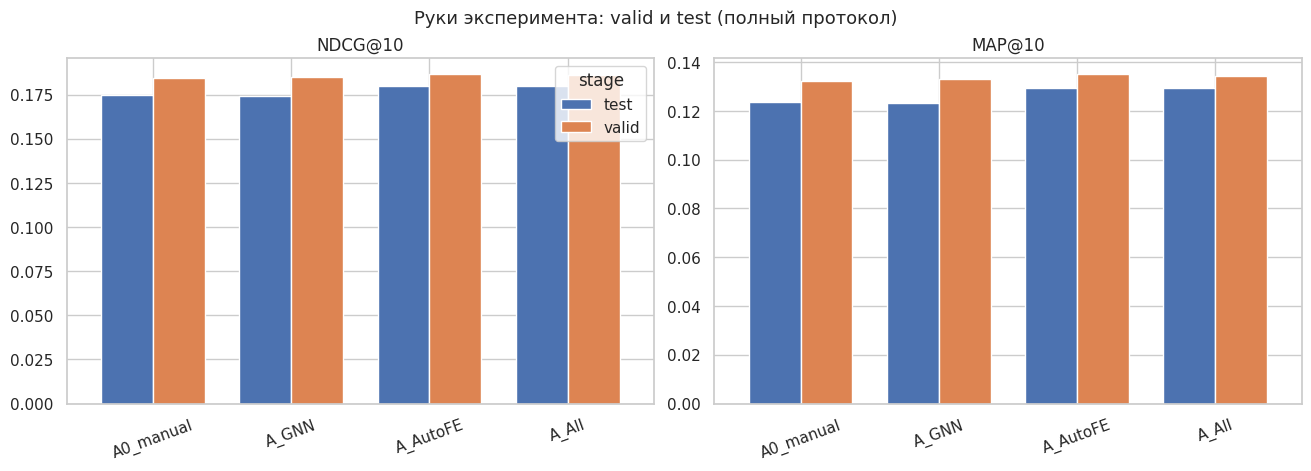


=== ВЕРДИКТ (test) ===
Лучшая автоматическая рука: A_AutoFE (dNDCG@10 = +0.00486, dMAP@10 = +0.00558, шум sigma(A0) = 0.00032)
Состав S1: ['ufe_genre_d14_all_count', 'ufe_country_d14_all_count', 'ufe_genre_all_recency', 'ufe_genre_w7_all_mean_watched', 'ufe_age_d7_all_log1p_count', 'ufe_country_w14_all_mean_watched', 'ufe_genre_all_all_mean_logdur']
Drift (H4): Спирмен=0.967, Jaccard топ-30=0.875

Топ-20 признаков A_All (auto = найдено автоматически):


,feature,importance,source
0,ials_score,0.031358,manual
1,popularity_1d,0.028127,manual
2,log1p_popularity_1d,0.023701,manual
3,log1p_popularity_7d,0.010740,manual
4,popularity_7d,0.010731,manual
5,i_release_year,0.003792,manual
6,popularity_all,0.003034,manual
7,popularity_30d,0.002494,manual
8,log1p_popularity_30d,0.002096,manual
9,ufe_genre_d14_all_count,0.001992,auto


Суммарная важность авто-признаков по рукам:
  A0_manual: авто-признаки в топ-20: 0, суммарная важность авто: 0.0000
  A_GNN: авто-признаки в топ-20: 0, суммарная важность авто: 0.0001
  A_AutoFE: авто-признаки в топ-20: 3, суммарная важность авто: 0.0053
  A_All: авто-признаки в топ-20: 3, суммарная важность авто: 0.0054

Вычислительные затраты по стадиям:


,stage,seconds,minutes
0,"iALS(поиск, OOF)",10.3,0.2
1,OOF-группы(поиск),9.5,0.2
2,"46 признаков(поиск, OOF)",5.3,0.1
3,компиляция спеков(OOF),70.6,1.2
4,"GNN(поиск, OOF)",16.0,0.3
5,GNN-производные(OOF),2.4,0.0
6,"iALS(поиск, valid)",11.0,0.2
7,"GNN(поиск, valid)",11.1,0.2
8,компиляция спеков(valid-pool),54.4,0.9
9,iALS top-100(поиск),3.2,0.1


Всего фитов ранкера: 110 (моделей)
CPU times: user 1h 30min 51s, sys: 2min 16s, total: 1h 33min 7s
Wall time: 26min 1s


In [ ]:
%%time

# ---------------------------------------------------------------------------
# Анализ: сводная таблица, дельты с порогом шума, важности, бюджеты
# ---------------------------------------------------------------------------

results_df = pd.DataFrame(VALID_RESULTS + TEST_RESULTS)
a0_test = [r for r in TEST_RESULTS if r["arm"] == "A0_manual"][0]
a0_valid = [r for r in VALID_RESULTS if r["arm"] == "A0_manual"][0]
results_df["delta_NDCG_vs_A0"] = results_df.apply(
    lambda r: (r["NDCG@10"] - (a0_test if r["stage"] == "test" else a0_valid)["NDCG@10"]), axis=1)

print("=== СВОДНАЯ ТАБЛИЦА (полный протокол) ===")
display(results_df[["stage", "arm", "users", "P@10", "R@10", "MAP@10", "NDCG@10", "MRR@10",
                    "Coverage@10", "sigma_NDCG", "delta_NDCG_vs_A0"]])

metric_cols = [f"NDCG@{CFG.k_recommend}", f"MAP@{CFG.k_recommend}"]
arm_order = list(ARMS)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True, sharey=False)
for ax, metric in zip(axes, metric_cols):
    tmp = results_df.pivot(index="arm", columns="stage", values=metric).reindex(arm_order)
    tmp.plot(kind="bar", ax=ax, width=0.75, legend=(metric == metric_cols[0]))
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Руки эксперимента: valid и test (полный протокол)", fontsize=13)
plt.show()

# --- вердикт по гипотезам (числа для статьи) ---
best_arm = max([r for r in TEST_RESULTS if r["arm"] != "A0_manual"], key=lambda r: r["NDCG@10"])
print("\n=== ВЕРДИКТ (test) ===")
print(f"Лучшая автоматическая рука: {best_arm['arm']} "
      f"(dNDCG@10 = {best_arm['NDCG@10'] - a0_test['NDCG@10']:+.5f}, "
      f"dMAP@10 = {best_arm['MAP@10'] - a0_test['MAP@10']:+.5f}, "
      f"шум sigma(A0) = {test_sigma['A0_manual']:.5f})")
print(f"Состав S1: {S1_SPECS}")
print(f"Drift (H4): Спирмен={DRIFT['spearman_IG']:.3f}, Jaccard топ-30={DRIFT['top30_jaccard']:.3f}")

# --- важности признаков финальных моделей (авто-фичи подсвечены) ---
IMPORTANCES = {}
auto_cols = set(S1_SPECS) | set(GNN_DERIV_FEATURES)
for arm, feats in ARMS.items():
    _paths = [CKPT / f"final_{arm}_{s}.cbm" for s in CB_SEEDS]
    if not all(p.exists() for p in _paths):
        print(f"  {arm}: нет финальных моделей — важности пропущены")
        continue
    _cols = list(dict.fromkeys(list(feats) + ["label", "group_id"]))
    _vp_arm = pd.read_parquet(F_VP, columns=_cols)   # только столбцы руки: VP не резидентен
    pool_final = make_pool(_vp_arm, feats)
    del _vp_arm
    gc.collect()
    try:
        _ms = []
        for _p in _paths:
            _m = CatBoostRanker()
            _m.load_model(str(_p))
            _ms.append(_m)
        imp = np.mean([m.get_feature_importance(pool_final) for m in _ms], axis=0)
        del _ms
    except Exception as e:
        print(f"  {arm}: важности недоступны ({type(e).__name__}) — пропускаю")
        del pool_final
        gc.collect()
        continue
    IMPORTANCES[arm] = pd.DataFrame({
        "feature": feats, "importance": imp,
        "source": ["auto" if f in auto_cols else "manual" for f in feats],
    }).sort_values("importance", ascending=False).reset_index(drop=True)
    del pool_final
    gc.collect()
    _ram_trim()
if IMPORTANCES:
    imp_table = IMPORTANCES["A_All"] if "A_All" in IMPORTANCES else next(iter(IMPORTANCES.values()))
    print("\nТоп-20 признаков A_All (auto = найдено автоматически):")
    display(imp_table.head(20))
    print("Суммарная важность авто-признаков по рукам:")
    for arm in ARMS:
        if arm not in IMPORTANCES:
            continue
        t = IMPORTANCES[arm]
        print(f"  {arm}: авто-признаки в топ-20: {int((t.head(20)['source'] == 'auto').sum())}, "
              f"суммарная важность авто: {t[t['source'] == 'auto']['importance'].sum():.4f}")
else:
    print("Важности недоступны ни для одной руки")

# --- вычислительные затраты ---
budget = pd.DataFrame({"stage": TRACKER["stage"], "seconds": TRACKER["seconds"]})
budget["minutes"] = (budget["seconds"] / 60).round(1)
print("\nВычислительные затраты по стадиям:")
display(budget)
print(f"Всего фитов ранкера: {TRACKER['fits']} (моделей)")


In [ ]:
# --- Сохранение артефактов ---
results_df.to_csv(ARTIFACTS_DIR / "autofe_results.csv", index=False)
imp_all = []
for arm, t in IMPORTANCES.items():
    t = t.copy(); t["arm"] = arm
    imp_all.append(t)
if imp_all:
    pd.concat(imp_all, ignore_index=True).to_csv(ARTIFACTS_DIR / "feature_importances.csv", index=False)
budget.to_csv(ARTIFACTS_DIR / "compute_budget.csv", index=False)

summary = {
    "experiment": "AutoFE + GNN поверх бейзлайна KION (46 ручных признаков)",
    "protocol": {
        "split": "temporal: train < valid_start, valid = 7d, test = last 7d",
        "as_of_features": "history only (no future information)",
        "search": "subsample users, OOF-slice inside train, selection on valid only",
        "gnn_retrained_per_cutoff": True,
        "test_used_once": True,
    },
    "arms": {arm: {"n_features": len(feats),
                   "extra": [f for f in feats if f not in FEATURES_46]}
             for arm, feats in ARMS.items()},
    "search": {
        "n_spec_space": len(ALL_SPECS) + len(GNN_DERIV_FEATURES),
        "survivors": len(SURVIVORS),
        "s1_specs": S1_SPECS,
        "base_ndcg_search": SEARCH_RESULT["base_ndcg"],
        "best_ndcg_search": SEARCH_RESULT["best_ndcg"],
        "drift": DRIFT,
        "fits_used": SEARCH_RESULT["budget_fits_used"],
    },
    "config": {
        "seed": CFG.seed, "fast_run": CFG.fast_run,
        "search_user_sample": CFG.search_user_sample,
        "k_recommend": CFG.k_recommend,
        "catboost": {"loss": "YetiRank", "seed_ensemble": len(CB_SEEDS), "seeds": list(CB_SEEDS),
                     "depth": CFG.cb_depth, "lr": CFG.cb_learning_rate,
                     "l2_leaf_reg": CFG.cb_l2_leaf_reg, "task_type": CB_TASK_TYPE,
                     "n_gpus": len(CB_DEVICES)},
        "gnn": {"dim": CFG.gnn_dim, "layers": CFG.gnn_layers, "epochs": CFG.gnn_epochs},
    },
    "results": results_df.to_dict(orient="records"),
    "compute_budget": {"total_fits": TRACKER["fits"],
                       "stages": dict(zip(TRACKER["stage"], TRACKER["seconds"]))},
}
with open(ARTIFACTS_DIR / "summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=str)

print(f"Артефакты сохранены в {ARTIFACTS_DIR.resolve()}:")
for p in sorted(ARTIFACTS_DIR.iterdir()):
    print(" -", p.name, f"({p.stat().st_size:,} байт)")


Артефакты сохранены в /kaggle/working/autofe_artifacts:
 - autofe_results.csv (1,576 байт)
 - ckpt (4,096 байт)
 - compute_budget.csv (986 байт)
 - feature_importances.csv (10,936 байт)
 - search_artifacts.json (57,831 байт)
 - summary.json (7,224 байт)


# 6. Ограничения и следующие шаги

**Ограничения протокола** (зафиксированы до эксперимента):

1. **Сигнал отбора** — valid-окно (одна неделя). Wrapper оценивает ΔNDCG на подвыборке кандидатов
   той же недели, что и early stopping ранкеров: valid-числа поиска слегка оптимистичны,
   итоговые выводы делаются по test (один заход).
2. **Бюджет перебора зафиксирован** (`wrapper_max_fits`) и одинаков для всех рук — приросты
   между руками нельзя объяснить разным объёмом вычислений. Отбор на подвыборке (скорость)
   с переносом состава S1 на полные данные — возможная потеря, которую измеряет A0-санити.
3. **GNN** — простейшая архитектура (2 слоя, dot-скординг, без входных признаков узлов):
   проверяется сама идея обучаемых представлений, а не потолок GNN-моделирования.
4. **Недетерминизм GPU** (CatBoost CUDA-редукции, sparse-ops torch) — при фиксированных seed
   метрики воспроизводятся в пределах ~1e-3; значимость дельт оценивается межсидовым sigma.

**Анализ для статьи**: дельты рук против шума; какие спеки вошли в S1 и совпали ли с прогнозом
(user×категория); вклад авто-блоков по важностям; потолок Candidate Recall; drift рейтинга IG.
Отрицательный результат (Δ ≈ 0 при здоровом потолке кандидатов) — содержательный вывод:
«ручной набор инженера уже насыщает сигнал ранкера; узкое место — генерация кандидатов».

**Следующие шаги**: мультинедельный OOF; негативы из кандидатов; тюнинг GNN (входные признаки
узлов, DistMult, больше слоёв); Featuretools-рука как внешний ориентир; холодный старт контента.
